# EDA · TT Dataset (TrainTicket + fault injection)

**Tujuan.** Mengenali isi *TT Dataset* sebelum dipakai untuk pemodelan (misalnya deteksi anomali atau *root-cause analysis* pada microservice): apa saja yang ada, seperti apa data mentahnya, dan masalah kualitas apa yang harus dibereskan lebih dulu.

**Apa itu TT Dataset?** Hasil eksperimen *fault injection* pada aplikasi benchmark microservice **TrainTicket** (27 service `ts-*`, dijalankan dengan Docker Compose). Pada setiap *run*, sebuah skrip memberi beban kerja ke aplikasi sambil menyuntikkan gangguan ke tiga service secara berurutan. Tiga jenis data direkam bersamaan (*modalitas*), ditambah satu berkas label:

| Modalitas | Berkas | Isi | Granularitas |
|---|---|---|---|
| **Metrics** | `metrics/<service>.csv` | CPU, memori, byte jaringan (rx/tx) tiap container | 1 baris per detik per service |
| **Traces** | `spans.json` | jejak pemanggilan antar service (format Jaeger) | banyak *span* per *trace* |
| **Logs** | `logs.json` | baris log aplikasi per service | teks bebas |
| **Label** | `TT.fault-<run>.json` | service, jenis, dan waktu fault | 9 fault per run |

**Cara memakai.** Jalankan dari atas ke bawah (*Run All*). Notebook ini **hanya membaca** data; tidak ada berkas data yang diubah atau diekstrak (arsip *no-fault* dibaca langsung dari `.tar.xz`). Waktu eksekusi sekitar 30–60 detik.

**Prasyarat.** Python ≥ 3.9 dengan `pandas` (≥ 2), `numpy`, `matplotlib`. Notebook harus dibuka dari folder `EADRO - APDM` (folder yang berisi `TT Dataset/`).

**Peta notebook**

1. Persiapan: path dan fungsi bantu
2. Inventaris: struktur folder, ukuran, duplikasi arsip
3. **Data mentah**: seperti apa isi tiap berkas (fault, metrics, logs, spans)
4. Memuat semua spans, duplikasi, dan hubungan log ↔ span
5. Pemeriksaan A: **sinkronisasi waktu** antara label/metrics dan spans/logs
6. Pemeriksaan B: span di luar jendela run dan tumpang tindih antar run
7. Pemeriksaan C: kontinuitas lalu lintas (beban kerja)
8. Pemeriksaan D: cakupan service (siapa yang benar-benar punya trafik)
9. Pemeriksaan E: desain label dan seberapa terlihat tiap fault di tiap modalitas
10. Pemeriksaan F: baseline *no-fault*
11. Ringkasan temuan dan resep pembersihan

**Istilah dan konvensi**

- **Run**: satu sesi percobaan ±108 menit. Dilabeli `R1…R9` (berfault) dan `N1…N3` (tanpa fault) agar ringkas.
- **Jendela fault**: rentang `[start, start + 600 s]` ketika satu fault aktif pada satu service.
- **Trace / span**: satu *trace* = satu permintaan end-to-end; satu *span* = satu langkah di dalamnya (misalnya satu panggilan HTTP). Span berbentuk pohon induk-anak.
- **Waktu** disimpan sebagai *epoch* (detik sejak 1970, UTC). Durasi span dalam **mikrodetik (µs)**; saya tampilkan sebagai ms bila perlu.
- **Dedup**: membuang baris yang persis sama, dijelaskan di bagian 4.

## 1. Persiapan

Sel berikut mengatur *import*, opsi tampilan, dan lokasi data. Dua hal penting:

- `RUNS` adalah daftar nama folder run di `data/` (contoh `2022-04-17T212101D2022-04-17T230842`). Nama folder berbentuk `TT.<waktu mulai>D<waktu selesai>`.
- Setiap run diberi label pendek `R1…R9` (urut waktu) di `RID`, dipakai di semua tabel.

In [5]:
from pathlib import Path
import json, re, tarfile, collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.max_rows", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "figure.autolayout": True})

# Path relatif terhadap lokasi notebook (folder "EADRO - APDM").
BASE    = Path("TT Dataset/TT Dataset")
DATA    = BASE / "data"          # 9 run dengan fault (sudah terekstrak)
NOFAULT = BASE / "no fault"      # 3 run tanpa fault (masih berupa arsip .tar.xz / .txz)
assert DATA.exists(), "Jalankan notebook dari folder yang berisi 'TT Dataset/' (EADRO - APDM)."

RUNS = sorted(p.name[3:] for p in DATA.glob("TT.2*") if p.is_dir())   # contoh: '2022-04-17T212101D2022-04-17T230842'
RID  = {run: f"R{i}" for i, run in enumerate(RUNS, 1)}                  # label pendek R1..R9
print(f"{len(RUNS)} run berfault ditemukan:")
for run in RUNS:
    print(" ", RID[run], run)

# Warna konsisten untuk jenis fault di semua grafik
COLORS = {"cpu_load": "#e07b39", "network_delay": "#4a7fb5", "network_loss": "#b5483a"}

9 run berfault ditemukan:
  R1 2022-04-17T212101D2022-04-17T230842
  R2 2022-04-18T102520D2022-04-18T121301
  R3 2022-04-18T121515D2022-04-18T140256
  R4 2022-04-18T150729D2022-04-18T165511
  R5 2022-04-18T165807D2022-04-18T184548
  R6 2022-04-18T184759D2022-04-18T203539
  R7 2022-04-18T203805D2022-04-18T222547
  R8 2022-04-18T222801D2022-04-19T001541
  R9 2022-04-19T001753D2022-04-19T020534


**Fungsi bantu.** Sel di bawah mendefinisikan pembaca untuk tiap modalitas. Ringkasnya:

| Fungsi | Fungsinya |
|---|---|
| `load_fault`, `fault_table` | membaca label; `fault_table` mengubahnya jadi tabel (service, fault, `t_start`, `t_end`) |
| `load_metrics` | membaca satu CSV metrics |
| `parse_logs` / `load_logs` | memecah tiap baris log dengan regex jadi kolom (waktu, level, logger, pesan) |
| `flatten_spans` | meratakan struktur JSON bersarang (trace → span → tag) menjadi satu tabel, satu baris per span |
| `print_trace` | mencetak satu trace sebagai pohon induk-anak |
| `utc`, `utc_str` | mengubah epoch menjadi waktu UTC yang terbaca |

Di `flatten_spans`, kolom `start` adalah epoch **detik**, sedangkan `dur` tetap **mikrodetik** seperti aslinya.

In [6]:
# ---------- waktu ----------
def utc(t):
    """epoch (detik) -> Timestamp UTC, untuk tampilan."""
    return pd.Timestamp(t, unit="s", tz="UTC")

def utc_str(t):
    return utc(t).strftime("%m-%d %H:%M:%S")

# ---------- fault.json (label) ----------
def load_fault(run, base=DATA):
    with open(base / f"TT.fault-{run}.json") as f:
        return json.load(f)

def fault_table(run, base=DATA):
    """Tabel fault: service, jenis fault, t_start, t_end (epoch pada jam 'fault.json')."""
    ft = pd.DataFrame(load_fault(run, base)["faults"])
    ft["service"] = ft["name"].str.extract(r"^dockercomposemanifests_(ts-.+?)_\d+$")[0]
    ft["t_start"] = ft["start"]
    ft["t_end"]   = ft["start"] + ft["duration"]
    return ft[["service", "fault", "t_start", "t_end", "duration"]]

# ---------- metrics ----------
def load_metrics(run, service, base=DATA):
    return pd.read_csv(base / f"TT.{run}" / "metrics" / f"{service}.csv")

# ---------- logs ----------
LOG_RE = re.compile(
    r"^(?P<ts>\d{4}-\d\d-\d\d \d\d:\d\d:\d\d\.\d+)\s+(?P<level>[A-Z]+)\s+(?P<pid>\d+) --- "
    r"\[(?P<thread>[^\]]*)\]\s+(?P<logger>\S+)\s*: (?P<msg>.*)$", re.S)

def parse_logs(raw):
    """raw = isi logs.json (dict service -> list baris). Hasil: DataFrame satu baris per baris log."""
    rows = []
    for svc, lines in raw.items():
        for ln in lines:
            m = LOG_RE.match(ln)
            if m:
                rows.append((svc, m["ts"], m["level"], m["thread"], m["logger"], m["msg"]))
            else:
                rows.append((svc, None, None, None, None, ln))
    df = pd.DataFrame(rows, columns=["service", "ts_str", "level", "thread", "logger", "msg"])
    ts = pd.to_datetime(df["ts_str"], utc=True)          # string tanpa zona -> dianggap UTC (terbukti di bagian 5)
    df["t"] = (ts - pd.Timestamp("1970-01-01", tz="UTC")).dt.total_seconds()
    return df

def load_logs(run, base=DATA):
    with open(base / f"TT.{run}" / "logs.json") as f:
        return parse_logs(json.load(f))

# ---------- spans ----------
SPAN_COLS = ["traceID", "spanID", "parent", "service", "op", "kind", "method", "status", "url", "error", "start", "dur"]

def flatten_spans(raw):
    """raw = isi spans.json (list trace). Hasil: satu baris per span.
    start = epoch detik (UTC), dur = durasi dalam MIKRODETIK (sesuai aslinya)."""
    rows = []
    for tr in raw:
        proc = {k: v["serviceName"] for k, v in tr["processes"].items()}
        for s in tr["spans"]:
            tg = {t["key"]: t["value"] for t in s["tags"]}
            parent = s["references"][0]["spanID"] if s["references"] else None
            rows.append((tr["traceID"], s["spanID"], parent, proc[s["processID"]], s["operationName"],
                         tg.get("span.kind"), tg.get("http.method"), tg.get("http.status_code"),
                         tg.get("http.url"), tg.get("error"), s["startTime"] / 1e6, s["duration"]))
    return pd.DataFrame(rows, columns=SPAN_COLS)

def load_spans_raw(run, base=DATA):
    with open(base / f"TT.{run}" / "spans.json") as f:
        return json.load(f)

def print_trace(df_trace):
    """Cetak satu trace sebagai pohon induk-anak."""
    ids = set(df_trace["spanID"])
    kids = collections.defaultdict(list)
    for r in df_trace.sort_values("start").itertuples():
        kids[r.parent if r.parent in ids else None].append(r)
    def rec(parent, depth):
        for r in kids[parent]:
            print(f"{'    ' * depth}{r.service} · {r.op} [{r.kind}] {r.dur / 1000:,.1f} ms")
            rec(r.spanID, depth + 1)
    rec(None, 0)

print("helper siap")

helper siap


## 2. Inventaris

**Struktur folder** (setelah `TT Dataset.zip` diekstrak):

```
TT Dataset/TT Dataset/
├── TT-all.txz                              ← arsip (ternyata salinan data/, lihat pemeriksaan di bawah)
├── data/                                   ← 9 run BERFAULT, sudah terekstrak
│   ├── TT.<mulai>D<selesai>/               ← satu folder per run
│   │   ├── spans.json                      ← traces (40–77 MB)
│   │   ├── logs.json                       ← logs per service (1–2 MB)
│   │   └── metrics/ts-*.csv                ← 27 file, satu per service
│   └── TT.fault-<mulai>D<selesai>.json     ← LABEL untuk run itu
└── no fault/                               ← 3 run TANPA fault, masih berupa arsip
    ├── TT-no-fault.txz                     ← berisi run 2022-04-20
    ├── TT.2022-04-21T105158D….tar.xz  (+ fault.json kosong)
    └── TT.2022-04-21T153246D….tar.xz  (+ fault.json kosong)
```

Folder `__MACOSX/` dan berkas `.DS_Store` hanyalah sisa pengarsipan di macOS, abaikan.

Sel pertama merangkum 9 run berfault; sel kedua membuktikan apakah `TT-all.txz` memuat sesuatu yang tidak ada di `data/`.

In [7]:
rows = []
for run in RUNS:
    d = DATA / f"TT.{run}"
    fj = load_fault(run)
    rows.append({
        "run": RID[run],
        "folder": run,
        "n_fault": len(fj["faults"]),
        "durasi_menit": (fj["end"] - fj["start"]) / 60,
        "spans_MB": (d / "spans.json").stat().st_size / 1e6,
        "logs_MB": (d / "logs.json").stat().st_size / 1e6,
        "n_metrics_csv": len(list((d / "metrics").glob("*.csv"))),
    })
inv = pd.DataFrame(rows).set_index("run")
display(inv.round(1))
print("Total ukuran folder data/ : %.0f MB" % (sum(p.stat().st_size for p in DATA.rglob("*") if p.is_file()) / 1e6))

,folder,n_fault,durasi_menit,spans_MB,logs_MB,n_metrics_csv
run,,,,,,
R1,2022-04-17T212101D2022-04-17T230842,9,107.7,42.8,1.7,27
R2,2022-04-18T102520D2022-04-18T121301,9,107.7,76.9,2.1,27
R3,2022-04-18T121515D2022-04-18T140256,9,107.7,76.8,2.0,27
R4,2022-04-18T150729D2022-04-18T165511,9,107.7,43.4,1.1,27
R5,2022-04-18T165807D2022-04-18T184548,9,107.7,43.3,1.8,27
R6,2022-04-18T184759D2022-04-18T203539,9,107.7,43.5,1.9,27
R7,2022-04-18T203805D2022-04-18T222547,9,107.7,41.6,1.8,27
R8,2022-04-18T222801D2022-04-19T001541,9,107.7,41.6,1.8,27
R9,2022-04-19T001753D2022-04-19T020534,9,107.7,41.2,1.6,27


Total ukuran folder data/ : 597 MB


In [8]:
# Apakah TT-all.txz hanya salinan folder data/ ?  (hanya membaca daftar isi arsip, tidak mengekstrak)
with tarfile.open(BASE / "TT-all.txz", "r:xz") as tf:
    in_tar = {m.name: m.size for m in tf if m.isfile()}
on_disk = {str(p.relative_to(BASE)): p.stat().st_size
           for p in DATA.rglob("*") if p.is_file() and p.name != ".DS_Store"}
print("file di TT-all.txz :", len(in_tar))
print("file di data/      :", len(on_disk))
print("nama hanya di arsip:", sorted(set(in_tar) - set(on_disk))[:5])
print("nama hanya di disk :", sorted(set(on_disk) - set(in_tar))[:5])
print("ukuran berbeda     :", [k for k in in_tar if k in on_disk and in_tar[k] != on_disk[k]][:5])

file di TT-all.txz : 270
file di data/      : 270
nama hanya di arsip: []
nama hanya di disk : []
ukuran berbeda     : []


> **Temuan 2**
> - Ada **9 run berfault**, masing-masing ±107,7 menit dengan 9 fault dan 27 file metrics. Ukuran `spans.json` terbagi dua kelompok: ±42 MB (R1, R4–R9) dan ±77 MB (R2, R3). R2 dan R3 lebih besar karena memuat lebih banyak trace di luar waktu run (dibahas di bagian 6).
> - `TT-all.txz` **identik** dengan folder `data/` (270 file, nama dan ukuran sama). Cukup pakai salah satu; memuat keduanya hanya menggandakan data.

## 3. Data mentah

Bagian ini menampilkan isi mentah tiap berkas, apa adanya, lengkap dengan cara membacanya. Semua contoh diambil dari **R1** (`2022-04-17T212101…`).

### 3.1 Label: `TT.fault-<run>.json`

Berkas JSON kecil (±1,5 KB). Strukturnya:

- `start`, `end`: awal dan akhir run (epoch detik, bilangan pecahan).
- `faults[]`: daftar fault, masing-masing berisi
  - `name`: nama *container* Docker Compose, berbentuk `dockercomposemanifests_<service>_1` (nama service ada di tengah),
  - `fault`: salah satu dari `cpu_load`, `network_delay`, `network_loss`,
  - `start`: kapan fault dimulai (epoch detik), `duration`: lama fault (detik).

`fault_table` mengekstrak nama service dari `name` dan menghitung `t_end = start + duration`.

In [9]:
run = RUNS[0]
print("== isi mentah TT.fault-<run>.json (R1, dipotong) ==")
print(json.dumps(load_fault(run), indent=2)[:700], "...\n")

ft = fault_table(run)
ft["mulai (jam fault.json, UTC)"]  = ft["t_start"].map(utc_str)
ft["selesai (jam fault.json, UTC)"] = ft["t_end"].map(utc_str)
ft["jeda ke fault berikutnya (s)"] = (ft["t_start"].shift(-1) - ft["t_end"]).round(0)
display(ft[["service", "fault", "duration", "mulai (jam fault.json, UTC)", "selesai (jam fault.json, UTC)", "jeda ke fault berikutnya (s)"]])

== isi mentah TT.fault-<run>.json (R1, dipotong) ==
{
  "start": 1650172861.377429,
  "faults": [
    {
      "name": "dockercomposemanifests_ts-food-service_1",
      "fault": "cpu_load",
      "start": 1650172864.064904,
      "duration": 600
    },
    {
      "name": "dockercomposemanifests_ts-food-service_1",
      "fault": "network_delay",
      "start": 1650173578.637172,
      "duration": 600
    },
    {
      "name": "dockercomposemanifests_ts-food-service_1",
      "fault": "network_loss",
      "start": 1650174303.018547,
      "duration": 600
    },
    {
      "name": "dockercomposemanifests_ts-travel-service_1",
      "fault": "cpu_load",
      "start": 1650175017.93866,
      "duration": 600
    },
    {
      "name": "dockerc ...



,service,fault,duration,"mulai (jam fault.json, UTC)","selesai (jam fault.json, UTC)",jeda ke fault berikutnya (s)
0,ts-food-service,cpu_load,600,04-17 05:21:04,04-17 05:31:04,115.0
1,ts-food-service,network_delay,600,04-17 05:32:58,04-17 05:42:58,124.0
2,ts-food-service,network_loss,600,04-17 05:45:03,04-17 05:55:03,115.0
3,ts-travel-service,cpu_load,600,04-17 05:56:57,04-17 06:06:57,114.0
4,ts-travel-service,network_delay,600,04-17 06:08:52,04-17 06:18:52,124.0
5,ts-travel-service,network_loss,600,04-17 06:20:56,04-17 06:30:56,115.0
6,ts-contacts-service,cpu_load,600,04-17 06:32:52,04-17 06:42:52,114.0
7,ts-contacts-service,network_delay,600,04-17 06:44:46,04-17 06:54:46,124.0
8,ts-contacts-service,network_loss,600,04-17 06:56:50,04-17 07:06:50,NaN


**Cara membaca.** Setiap run menyuntikkan **3 jenis fault ke tiap dari 3 service**, berurutan satu per satu, tidak pernah dua sekaligus. Satu fault aktif **600 detik**, lalu ada jeda sekitar **114–124 detik** sebelum fault berikutnya (kolom terakhir). Jadi dalam ±108 menit nyaris tidak ada waktu "tenang"; ini berdampak pada baseline (dibahas di bagian 10).

Kolom waktu di tabel memakai "jam `fault.json`". Ingat ini: jam inilah yang nanti ternyata **tidak sama** dengan jam di spans dan logs (bagian 5).

### 3.2 Metrics: `metrics/<service>.csv`

Satu CSV per service, **satu baris per detik** selama run (±6.461 baris). Kolom:

| Kolom | Arti (dari pola data; **satuan tidak didokumentasikan** di dataset) |
|---|---|
| `timestamp` | epoch detik, naik 1 per baris |
| `cpu_usage_system`, `cpu_usage_user`, `cpu_usage_total` | penggunaan CPU. Nilai `cpu_usage_total` ≈ 0,001 saat idle dan ±30–80 saat fault `cpu_load`, jadi tampak dalam **persen** |
| `memory_usage`, `memory_working_set` | memori; nilainya kecil (≈ 0,0047) dan hampir konstan, kemungkinan fraksi dari memori host |
| `rx_bytes`, `tx_bytes` | byte jaringan diterima/dikirim; banyak bernilai 0 dengan lonjakan sesekali |

In [10]:
run = RUNS[0]
m = load_metrics(run, "ts-food-service")
print("== 5 baris pertama ts-food-service.csv (mentah) ==")
display(m.head())
print("jumlah baris:", len(m), "| selang timestamp (detik):", sorted(m["timestamp"].diff().dropna().unique())[:5])

t0 = load_fault(run)["faults"][0]["start"]   # fault pertama: cpu_load pada ts-food-service
print("\n== beberapa baris SAAT cpu_load aktif (fault pertama dimulai di epoch %.0f) ==" % t0)
display(m[(m["timestamp"] >= t0 + 60) & (m["timestamp"] <= t0 + 63)])

print("== ringkasan statistik seluruh run ==")
display(m.drop(columns="timestamp").describe().T)

== 5 baris pertama ts-food-service.csv (mentah) ==


,timestamp,cpu_usage_system,cpu_usage_total,cpu_usage_user,memory_usage,memory_working_set,rx_bytes,tx_bytes
0,1650172861,0.01,0.017287,0.01,0.004667,0.004644,496.0,70.0
1,1650172862,0.01,0.017287,0.01,0.004667,0.004644,496.0,70.0
2,1650172863,0.08,1.167646,1.10,0.005344,0.005315,385.0,190.0
3,1650172864,0.06,32.118033,32.10,0.004769,0.004746,0.0,0.0
4,1650172865,0.06,32.118033,32.10,0.004769,0.004746,0.0,0.0


jumlah baris: 6461 | selang timestamp (detik): [np.float64(1.0)]

== beberapa baris SAAT cpu_load aktif (fault pertama dimulai di epoch 1650172864) ==


,timestamp,cpu_usage_system,cpu_usage_total,cpu_usage_user,memory_usage,memory_working_set,rx_bytes,tx_bytes
64,1650172925,0.065,36.974647,36.81,0.004756,0.004732,0.0,0.0
65,1650172926,0.080,42.805053,42.56,0.004762,0.004739,0.0,0.0
66,1650172927,0.080,42.805053,42.56,0.004762,0.004739,0.0,0.0


== ringkasan statistik seluruh run ==


,count,mean,std,min,25%,50%,75%,max
cpu_usage_system,6461.0,0.007957,0.024964,0.000000,0.000000,0.000000,0.000000,0.270000
cpu_usage_total,6461.0,4.320923,14.049958,0.000332,0.000868,0.001119,0.001524,81.910483
cpu_usage_user,6461.0,4.300971,13.988512,0.000000,0.000000,0.000000,0.000000,81.740000
memory_usage,6461.0,0.004674,0.000030,0.004665,0.004665,0.004665,0.004665,0.005344
memory_working_set,6461.0,0.004650,0.000028,0.004641,0.004641,0.004641,0.004641,0.005315
rx_bytes,6461.0,66.646494,177.006492,0.000000,0.000000,0.000000,0.000000,1832.000000
tx_bytes,6461.0,25.841356,58.835493,0.000000,0.000000,0.000000,0.000000,405.000000


**Hal yang perlu diperhatikan**

- Nilai kadang **tidak berubah selama beberapa detik berturut-turut** (lihat dua baris pertama dan baris 3–4: `cpu_usage_total` sama persis). Artinya sumber metrics tampaknya menahan nilai terakhir (*sample-and-hold*), jadi resolusi efektifnya lebih kasar daripada 1 Hz.
- `memory_*` nyaris tidak bergerak (std ≈ 3·10⁻⁵): informasinya rendah, jangan berharap fault muncul di sini.
- Baris ke-60-an saat `cpu_load` aktif menunjukkan CPU sudah 37–43, sedangkan saat idle ≈ 0,001. **Fault CPU sangat jelas di metrics.**

### 3.3 Logs: `logs.json`

Berupa `dict`: `{nama_service: [baris teks, …]}`. Tiap baris adalah log aplikasi Spring Boot dengan format

```
<tanggal> <jam.ms>  <LEVEL> <pid> --- [<thread>] <logger> : <pesan>
```

`parse_logs` memecahnya dengan regex. Waktu di log berupa **string tanpa zona waktu**; zonanya dibuktikan di bagian 5.

In [12]:
run = RUNS[0]
with open(DATA / f"TT.{run}" / "logs.json") as f:
    raw_logs = json.load(f)
print("== struktur: dict {nama_service: [baris teks, ...]} ==")
print({k: len(v) for k, v in raw_logs.items()})

print("\n== 6 baris mentah pertama ts-travel-service ==")
for ln in raw_logs["ts-travel-service"][:6]:
    print(" ", ln[:200])

lg = parse_logs(raw_logs)
print("\nbaris yang tidak cocok pola regex:", lg["ts_str"].isna().sum(), "dari", len(lg))
print("\n== level log ==")
print(lg["level"].value_counts().to_string())
print("\n== logger terbanyak ==")
print(lg["logger"].value_counts().head(8).to_string())
print("\n== 5 baris log milik ts-food-service (service yang di-fault di run ini) ==")
for ln in raw_logs["ts-food-service"]:
    print(" ", ln[:210])

== struktur: dict {nama_service: [baris teks, ...]} ==
{'ts-auth-service': 528, 'ts-assurance-service': 176, 'ts-basic-service': 528, 'ts-config-service': 0, 'ts-contacts-service': 710, 'ts-food-map-service': 0, 'ts-food-service': 3, 'ts-inside-payment-service': 0, 'ts-notification-service': 0, 'ts-order-other-service': 176, 'ts-order-service': 704, 'ts-payment-service': 0, 'ts-preserve-service': 965, 'ts-price-service': 0, 'ts-route-service': 880, 'ts-route-plan-service': 0, 'ts-seat-service': 0, 'ts-security-service': 968, 'ts-ticketinfo-service': 352, 'ts-train-service': 0, 'ts-travel-service': 2301, 'ts-travel-plan-service': 0, 'ts-travel2-service': 0, 'ts-user-service': 0, 'ts-cancel-service': 0, 'ts-station-service': 264, 'ts-verification-code-service': 440}

== 6 baris mentah pertama ts-travel-service ==
  2022-04-17 13:22:01.624  INFO 1 --- [io-12346-exec-8] travel.controller.TravelController       : [Travel Service] Query TripResponse
  2022-04-17 13:22:01.633  INFO 1 --- [io-

**Hal yang perlu diperhatikan**

- **Semua baris berlevel `INFO`**, tidak ada `WARN`/`ERROR`. Mencari kesalahan berdasarkan level tidak akan menemukan apa pun; isi pesan yang harus dibaca.
- Sekitar **40% baris adalah `Span reported: <traceID>:<spanID>:<parentID>:<flags> - <operasi>`** (logger `LoggingReporter`). Itu jejak reporter Jaeger yang menautkan log ke span (dibuktikan di bagian 4).
- Banyak service **tidak punya log sama sekali** (di R1 ada 13 dari 27). Service yang tidak menerima trafik hampir tidak mencatat apa-apa.
- Contoh menarik: `ts-food-service`, yang di-fault di R1, hanya punya **3 baris log**, semuanya tentang koneksi MongoDB (`Exception in monitor thread while connecting…`, lalu berhasil tersambung kembali 23 detik kemudian). Itu satu-satunya jejak fault jaringan di service tersebut; waktunya kita cocokkan di bagian 5.
- Sebagian pesan memuat token JWT dan kredensial akun uji (`fdse_microservice`). Ini data benchmark, tetapi jangan disalin ke laporan atau repositori publik.

In [13]:
run = RUNS[0]
raw = load_spans_raw(run)
print("tipe:", type(raw).__name__, "| jumlah elemen (trace):", len(raw))
print("kunci tiap trace :", list(raw[0].keys()))
print("kunci tiap span  :", list(raw[0]["spans"][0].keys()))

sp = raw[0]["spans"][1]
print("\n== satu span mentah (JSON) ==")
print(json.dumps(sp, indent=1)[:1500])
print("\n== 'processes' pada trace itu (pemetaan processID -> service) ==")
print({k: v["serviceName"] for k, v in raw[0]["processes"].items()})

tipe: list | jumlah elemen (trace): 1908
kunci tiap trace : ['traceID', 'spans', 'processes', 'warnings']
kunci tiap span  : ['traceID', 'spanID', 'flags', 'operationName', 'references', 'startTime', 'duration', 'tags', 'logs', 'processID', 'warnings']

== satu span mentah (JSON) ==
{
 "traceID": "5d4e8e9f7697c45c",
 "spanID": "7a154a077e439226",
 "flags": 1,
 "operationName": "verifyCode",
 "references": [
  {
   "refType": "CHILD_OF",
   "traceID": "5d4e8e9f7697c45c",
   "spanID": "df62a7266345e4ec"
  }
 ],
 "startTime": 1650200686487738,
 "duration": 1499,
 "tags": [
  {
   "key": "http.status_code",
   "type": "int64",
   "value": 200
  },
  {
   "key": "http.url",
   "type": "string",
   "value": "http://ts-auth-service:12340/api/v1/verifycode/verify/AAAA"
  },
  {
   "key": "component",
   "type": "string",
   "value": "java-web-servlet"
  },
  {
   "key": "span.kind",
   "type": "string",
   "value": "server"
  },
  {
   "key": "http.method",
   "type": "string",
   "value": "GE

### 3.4 Traces: `spans.json`

Format ekspor **Jaeger**: sebuah `list`, satu elemen per *trace*. Setiap trace punya:

- `traceID`: pengenal satu permintaan end-to-end,
- `spans[]`: daftar langkah di dalamnya,
- `processes`: kamus `processID → serviceName` (nama service ada di sini, **bukan** di span),
- `warnings`.

Setiap span punya `spanID`, `operationName`, `references` (menunjuk span **induk** lewat `CHILD_OF`), `startTime` (**mikrodetik** epoch), `duration` (**mikrodetik**), `tags` (daftar `key/type/value`, misalnya `http.status_code`, `http.url`, `span.kind`, `http.method`), dan `logs` (event seperti `preHandle`/`postHandle`).

Struktur bersarang seperti ini tidak nyaman dianalisis, jadi `flatten_spans` meratakannya menjadi satu baris per span. Kolom `parent` menunjuk `spanID` induk (`NaN` = span akar). Setelah itu kita cetak satu trace sebagai pohon.

In [14]:
flat_r1 = flatten_spans(raw)
print("hasil flatten:", flat_r1.shape)
display(flat_r1.head(6))

uniq_r1 = flat_r1.drop_duplicates(["traceID", "spanID"])
size = uniq_r1.groupby("traceID").size()
print("\nDistribusi jumlah span per trace (trace unik):")
print(size.value_counts().sort_index().to_string())
print("trace terbesar:", size.max(), "span")

# contoh pohon pemanggilan: trace dengan 9 span (mewakili alur 'query tiket')
example = size[size == 9].index[0]
tr = uniq_r1[uniq_r1["traceID"] == example]
print(f"\n== pohon trace {example} ({len(tr)} span) ==")
print_trace(tr)
del raw

hasil flatten: (18346, 12)


,traceID,spanID,parent,service,op,kind,method,status,url,error,start,dur
0,5d4e8e9f7697c45c,df62a7266345e4ec,5d4e8e9f7697c45c,ts-auth-service,GET,client,GET,200,http://ts-verification-code-service:15678/api/v1/verifycode/verify/AAAA,None,1.650201e+09,2975
1,5d4e8e9f7697c45c,7a154a077e439226,df62a7266345e4ec,ts-verification-code-service,verifyCode,server,GET,200,http://ts-auth-service:12340/api/v1/verifycode/verify/AAAA,None,1.650201e+09,1499
2,5d4e8e9f7697c45c,5d4e8e9f7697c45c,NaN,ts-auth-service,getToken,server,POST,200,http://ts-auth-service:12340/api/v1/users/login,None,1.650201e+09,126233
3,d0fc26a00e4ff31a,e4f61a755533af87,f87acfda9483723e,ts-verification-code-service,verifyCode,server,GET,200,http://ts-auth-service:12340/api/v1/verifycode/verify/AAAA,None,1.650201e+09,1927
4,d0fc26a00e4ff31a,f87acfda9483723e,d0fc26a00e4ff31a,ts-auth-service,GET,client,GET,200,http://ts-verification-code-service:15678/api/v1/verifycode/verify/AAAA,None,1.650201e+09,3674
5,d0fc26a00e4ff31a,d0fc26a00e4ff31a,NaN,ts-auth-service,getToken,server,POST,200,http://ts-auth-service:12340/api/v1/users/login,None,1.650201e+09,127644



Distribusi jumlah span per trace (trace unik):
1     300
2     100
3     200
7       1
8      13
9      98
15      3
18      1
21      1
22      1
23     97
77      1
81      1
trace terbesar: 81 span

== pohon trace 119ec2b0aa94dc6b (9 span) ==
ts-preserve-service · preserve [server] 20,701.5 ms
    ts-preserve-service · GET [client] 16.1 ms
        ts-security-service · check [server] 14.5 ms
            ts-security-service · GET [client] 4.9 ms
                ts-order-service · securityInfoCheck [server] 3.5 ms
            ts-security-service · GET [client] 5.0 ms
                ts-order-other-service · securityInfoCheck [server] 3.5 ms
    ts-preserve-service · GET [client] 14,312.4 ms
        ts-contacts-service · getContactsByContactsId [server] 3,009.0 ms


**Cara membaca pohon di atas.** Panggilan antar service muncul sebagai **pasangan span**:

- span `client` (di service pemanggil, misalnya `ts-preserve-service · GET [client]`), dan
- span `server` (di service yang dipanggil, misalnya `ts-security-service · check [server]`) sebagai anaknya.

Durasi span *client* mencakup durasi span *server* ditambah waktu jaringan. **Selisih client − server** karenanya mengukur latensi jaringan, dan itu penting untuk fault `network_delay`/`network_loss`.

Perhatikan juga pada contoh di atas: pemanggilan `ts-contacts-service` memakan 3.009 ms sementara span klien induknya 14.312 ms. Beberapa trace memang jauh lebih lambat dari rata-rata; pengaruh fault pada latensi dibahas di bagian 9.

Distribusi jumlah span per trace menunjukkan banyak trace kecil (1–3 span, mis. login dan verifikasi) dan dua alur besar (9 dan 23 span), plus beberapa trace langka sampai 81 span.

## 4. Memuat semua spans: duplikasi dan hubungan log ↔ span

Sel berikut memuat `spans.json` setiap run satu per satu (agar memori tidak penuh), meratakannya, lalu menghitung berapa banyak yang **duplikat**. Duplikat didefinisikan sebagai baris dengan `(traceID, spanID)` yang sama. Sel juga memeriksa apakah salinan-salinan itu **identik** (kolom `salinan_berbeda` = jumlah span yang salinannya punya `start`/`dur` berbeda).

In [15]:
SPANS, dup_rows = {}, []
for run in RUNS:
    raw = load_spans_raw(run)
    df = flatten_spans(raw)
    key = ["traceID", "spanID"]
    # Apakah salinan span yang sama selalu identik? (start/dur berbeda = konflik)
    conflict = int((df.groupby(key)[["start", "dur"]].nunique() > 1).any(axis=1).sum())
    uniq = df.drop_duplicates(key).reset_index(drop=True)
    SPANS[run] = uniq
    dup_rows.append({
        "run": RID[run],
        "objek_trace": len(raw), "traceID_unik": df["traceID"].nunique(),
        "baris_span": len(df), "span_unik": len(uniq),
        "faktor_duplikasi": len(df) / len(uniq), "salinan_berbeda": conflict,
    })
    del raw, df
dup = pd.DataFrame(dup_rows).set_index("run")
display(dup.round(2))
print("Total baris span: %d -> unik: %d  (%.0f%% baris adalah duplikat)" %
      (dup.baris_span.sum(), dup.span_unik.sum(), 100 * (1 - dup.span_unik.sum() / dup.baris_span.sum())))

,objek_trace,traceID_unik,baris_span,span_unik,faktor_duplikasi,salinan_berbeda
run,,,,,,
R1,1908,817,18346,4588,4.00,0
R2,3208,1350,33250,8304,4.00,0
R3,3108,1248,33332,8200,4.06,0
R4,1908,802,18544,4463,4.16,0
R5,1908,813,18429,4588,4.02,0
R6,1908,804,18491,4492,4.12,0
R7,1900,810,17846,4442,4.02,0
R8,1900,809,17850,4359,4.09,0
R9,1900,805,17673,4327,4.08,0


Total baris span: 193761 -> unik: 47763  (75% baris adalah duplikat)


> **Temuan 4a: `spans.json` sangat duplikat.**
> Dari **193.761** baris span hanya **47.763** yang unik: **75% baris adalah salinan**. Tiap span muncul rata-rata ±4 kali (faktor 4,0–4,2), dan semua salinan **identik** (0 konflik), jadi aman dibuang.
> Penyebab pastinya tidak terdokumentasi. Dugaan saya: data diambil dari Jaeger dengan beberapa kueri yang rentang waktunya bertumpuk, lalu hasilnya digabung tanpa dedup. Ini hanya dugaan, tetapi pola "salinan identik" konsisten dengannya.
> **Konsekuensi:** menghitung span/trace, rata-rata, dan persentase tanpa dedup akan menggandakan bobot sekitar 4×. Hasil di notebook ini semuanya **setelah dedup** (`SPANS[run]`).

Berikutnya: apakah log dan span konsisten? Log `Span reported: <traceID>:<spanID>…` seharusnya menunjuk span yang ada di `spans.json` run yang sama.

In [16]:
# Log "Span reported: <traceID>:<spanID>:<parentID>:<flags> - <operasi>" adalah jejak reporter Jaeger di log aplikasi.
# Pemeriksaan: apakah setiap span yang tercatat di log juga ada di spans.json pada run yang sama?
REP_RE = re.compile(r"Span reported: (\w+):(\w+):(\w+):(\d+) - (.*)$")
LOGS = {run: load_logs(run) for run in RUNS}

link_rows = []
for run in RUNS:
    lg = LOGS[run]
    rep = lg["msg"].str.extract(REP_RE)
    rep.columns = ["traceID", "spanID", "parentID", "flags", "op"]
    rep = rep.dropna(subset=["traceID"])
    have = set(zip(SPANS[run]["traceID"], SPANS[run]["spanID"]))
    found = np.mean([(a, b) in have for a, b in zip(rep["traceID"], rep["spanID"])]) if len(rep) else np.nan
    link_rows.append({"run": RID[run], "baris_log": len(lg), "baris_'Span reported'": len(rep),
                      "% ditemukan di spans.json": 100 * found})
display(pd.DataFrame(link_rows).set_index("run").round(1))

,baris_log,baris_'Span reported',% ditemukan di spans.json
run,,,
R1,8995,3606,98.8
R2,10916,4387,100.0
R3,10509,4223,99.8
R4,5663,2268,99.8
R5,9713,3905,99.2
R6,10016,4018,99.7
R7,9804,3934,99.6
R8,9494,3816,99.4
R9,8457,3387,98.7


> **Temuan 4b.** **98,7–100%** span yang tercatat di log ditemukan di `spans.json` pada run yang sama. Log dan trace saling konsisten, jadi baris `Span reported` bisa dipakai untuk **menautkan log ke trace** (join lewat `traceID`/`spanID`). Sisa ≤ 1,3% kemungkinan trace yang terpotong di tepi run.

## 5. Pemeriksaan A: sinkronisasi waktu

**Mengapa penting.** Label fault ada di `fault.json`, sedangkan efek fault terlihat di metrics, spans, dan logs. Kalau jam-jam itu tidak sama, label akan jatuh di waktu yang salah dan model belajar dari label yang meleset.

**Cara memeriksa.** Ada empat sumber waktu: nama folder, `fault.json`, metrics, dan spans/logs. Kita bandingkan semuanya terhadap satu acuan, awal run, lewat tiga bukti independen:

1. **Selisih awal dan akhir** antara log dan `fault.json` per run.
2. **Bukti dari log MongoDB** milik `ts-food-service` (hanya 3 baris, dicocokkan dengan jendela fault-nya).
3. **Bukti dari efek fault**: apakah span lambat jatuh di dalam jendela fault, **dengan dan tanpa** menggeser jam?

In [17]:
def folder_start_utc(run):
    """Nama folder 'TT.<YYYY-mm-ddTHHMMSS>D<...>' = jam lokal mesin pengumpul. Kita asumsikan UTC+8 lalu ubah ke UTC (diuji di bawah)."""
    naive = pd.to_datetime(run.split("D")[0], format="%Y-%m-%dT%H%M%S")
    return (naive - pd.Timedelta(hours=8)).tz_localize("UTC").timestamp()

sync_rows = []
for run in RUNS:
    fj, lg = load_fault(run), LOGS[run]
    mt = load_metrics(run, "ts-order-service")["timestamp"]
    f0 = folder_start_utc(run)
    sync_rows.append({
        "run": RID[run],
        "awal di nama folder (UTC+8→UTC)": utc_str(f0),
        "fault.json start (UTC)": utc_str(fj["start"]),
        "log pertama (UTC)":      utc_str(lg["t"].min()),
        "fault.start - folder (jam)":    (fj["start"] - f0) / 3600,
        "log_pertama - folder (menit)":  (lg["t"].min() - f0) / 60,
        "log_pertama - fault.start (jam)": (lg["t"].min() - fj["start"]) / 3600,
        "log_terakhir - fault.end (jam)":  (lg["t"].max() - fj["end"]) / 3600,
        "metrics_pertama - fault.start (detik)": mt.min() - fj["start"],
    })
sync = pd.DataFrame(sync_rows).set_index("run")
display(sync.round(3))

gaps = pd.concat([sync["log_pertama - fault.start (jam)"], sync["log_terakhir - fault.end (jam)"]])
OFFSET_S = int(round(gaps.median())) * 3600
print(f"Estimasi offset (spans/logs terhadap fault.json/metrics): {OFFSET_S/3600:+.0f} jam = {OFFSET_S} detik")

,awal di nama folder (UTC+8→UTC),fault.json start (UTC),log pertama (UTC),fault.start - folder (jam),log_pertama - folder (menit),log_pertama - fault.start (jam),log_terakhir - fault.end (jam),metrics_pertama - fault.start (detik)
run,,,,,,,,
R1,04-17 13:21:01,04-17 05:21:01,04-17 13:22:01,-8.0,1.007,8.017,7.985,-0.377
R2,04-18 02:25:20,04-17 18:25:20,04-18 02:26:20,-8.0,1.010,8.017,7.998,-0.521
R3,04-18 04:15:15,04-17 20:15:15,04-18 04:16:15,-8.0,1.006,8.017,7.991,-0.379
R4,04-18 07:07:29,04-17 23:07:29,04-18 07:08:29,-8.0,1.007,8.017,7.341,-0.406
R5,04-18 08:58:07,04-18 00:58:07,04-18 08:59:07,-8.0,1.015,8.017,7.985,-0.937
R6,04-18 10:47:59,04-18 02:47:59,04-18 10:48:59,-8.0,1.010,8.017,7.987,-0.576
R7,04-18 12:38:05,04-18 04:38:05,04-18 12:39:05,-8.0,1.008,8.017,7.987,-0.501
R8,04-18 14:28:01,04-18 06:28:01,04-18 14:29:01,-8.0,1.002,8.017,7.986,-0.139
R9,04-18 16:17:53,04-18 08:17:53,04-18 16:18:53,-8.0,1.002,8.017,7.990,-0.164


Estimasi offset (spans/logs terhadap fault.json/metrics): +8 jam = 28800 detik


> **Temuan 5a.**
> - Awal run di **nama folder**, bila dianggap jam lokal UTC+8, ternyata **sama persis** dengan log pertama (selisih ≈ 1 menit, yaitu login pertama workload) di semua 9 run. Jadi log dan spans memakai **UTC yang benar**.
> - `fault.json` mulai tepat **8,0 jam lebih awal** (−8,0 jam) dari nama folder di semua run, dan metrics berawal dalam < 1 detik dari `fault.json`. Jadi **`fault.json` dan metrics sejajar satu sama lain, tetapi keduanya 8 jam di belakang spans/logs.**
> - Selisih `log pertama − fault.start` = **8,017 jam** (8 jam + 1 menit login) di semua run; `log terakhir − fault.end` ≈ **7,99 jam**. Satu pengecualian: **R4 = 7,34 jam**. Lalu lintas R4 berhenti lebih awal; lihat bagian 7.
> - Pola "mundur tepat 8 jam" mirip konversi zona waktu yang terjadi **dua kali** pada pembuatan `fault.json` dan metrics. Ini penjelasan yang paling masuk akal tetapi tetap **dugaan**; yang terbukti dari data adalah offsetnya.
>
> Offset yang dipakai di seluruh notebook: `OFFSET_S = 28.800` detik (spans/logs = jam `fault.json` + 8 jam).

**Bukti 2: log MongoDB `ts-food-service`.**

In [18]:
# Bukti independen: ts-food-service di R1 nyaris tidak punya log (service ini tidak menerima trafik),
# tetapi 3 baris log-nya adalah error koneksi MongoDB. Apakah waktunya jatuh di jendela 'network_loss' setelah digeser?
run = RUNS[0]
ft = fault_table(run)
lg = LOGS[run]
food_logs = lg[lg["service"] == "ts-food-service"][["ts_str", "t", "logger", "msg"]].copy()
food_logs["msg"] = food_logs["msg"].str.slice(0, 85)

print("Jendela fault ts-food-service di R1, dinyatakan dalam jam LOG (jam fault.json + offset):")
for r in ft[ft["service"] == "ts-food-service"].itertuples():
    print(f"  {r.fault:14s} {utc_str(r.t_start + OFFSET_S)} -> {utc_str(r.t_end + OFFSET_S)}")
print("\nBaris log ts-food-service:")
display(food_logs[["ts_str", "logger", "msg"]])

Jendela fault ts-food-service di R1, dinyatakan dalam jam LOG (jam fault.json + offset):
  cpu_load       04-17 13:21:04 -> 04-17 13:31:04
  network_delay  04-17 13:32:58 -> 04-17 13:42:58
  network_loss   04-17 13:45:03 -> 04-17 13:55:03

Baris log ts-food-service:


,ts_str,logger,msg
1942,2022-04-17 13:51:40.108,org.mongodb.driver.cluster,Exception in monitor thread while connecting to server ts-food-mongo:27017
1943,2022-04-17 13:52:03.731,org.mongodb.driver.connection,"Opened connection [connectionId{localValue:20, serverValue:20}] to ts-food-mongo:2701"
1944,2022-04-17 13:52:04.146,org.mongodb.driver.cluster,Monitor thread successfully connected to server with description ServerDescription{ad


> **Temuan 5b.** **Ketiga** baris log (kegagalan koneksi **13:51:40**, koneksi dibuka ulang **13:52:03**, monitor tersambung **13:52:04**) jatuh **di dalam** jendela `network_loss` (13:45:03–13:55:03) setelah jam `fault.json` digeser +8 jam. Tanpa geseran, jendela itu ada di 05:45–05:55 dan tidak ada log yang cocok. Ini bukti independen ketiga, dari modalitas yang berbeda.

**Bukti 3: efek fault pada span.** Untuk setiap jendela fault kita lihat apakah ada span milik service yang di-fault di dalamnya, **tanpa geseran** vs **dengan geseran +8 jam**.

In [19]:
def window_stats(run, shift, kinds=("server", "client")):
    """Untuk tiap fault: median durasi span milik service yang di-fault, DI DALAM jendela fault vs DI LUAR jendela (baseline run yang sama).
    shift = detik yang ditambahkan ke jam fault.json agar sejajar dengan jam spans."""
    fj, ft = load_fault(run), fault_table(run)
    sp = SPANS[run]
    sp = sp[sp["kind"].isin(kinds)]
    lo, hi = fj["start"] + shift - 60, fj["end"] + shift + 60
    out = []
    for svc, g in ft.groupby("service", sort=False):
        s = sp[(sp["service"] == svc) & (sp["start"] >= lo) & (sp["start"] <= hi)]
        near = np.zeros(len(s), bool)                       # dekat jendela fault MANAPUN pada service ini (+- 60 s)
        for r in g.itertuples():
            near |= ((s["start"] >= r.t_start + shift - 60) & (s["start"] < r.t_end + shift + 60)).to_numpy()
        base = s[~near]
        for r in g.itertuples():
            w = s[(s["start"] >= r.t_start + shift) & (s["start"] < r.t_end + shift)]
            out.append({"run": RID[run], "service": svc, "fault": r.fault, "n_di_jendela": len(w),
                        "median_di_jendela_ms": w["dur"].median() / 1000, "n_baseline": len(base),
                        "median_baseline_ms": base["dur"].median() / 1000})
    return pd.DataFrame(out)

eff0 = pd.concat([window_stats(r, 0) for r in RUNS], ignore_index=True)
eff8 = pd.concat([window_stats(r, OFFSET_S) for r in RUNS], ignore_index=True)
cmp_ = eff0[["run", "service", "fault", "n_di_jendela"]].rename(columns={"n_di_jendela": "n_tanpa_geser"})
cmp_["n_dengan_geser"] = eff8["n_di_jendela"].values
summary = cmp_.groupby("fault").agg(jendela=("fault", "size"),
                                    jendela_ada_span_tanpa_geser=("n_tanpa_geser", lambda s: int((s > 0).sum())),
                                    jendela_ada_span_dengan_geser=("n_dengan_geser", lambda s: int((s > 0).sum())))
display(summary)

,jendela,jendela_ada_span_tanpa_geser,jendela_ada_span_dengan_geser
fault,,,
cpu_load,27,0,13
network_delay,27,0,13
network_loss,27,0,13


> **Temuan 5c.** Tanpa geseran, **tidak ada satu pun** dari 81 jendela fault yang berisi span (0 dari 27 per jenis fault). Dengan geseran +8 jam, **13 dari 27** jendela per jenis fault berisi span. (Sisanya 14 ada pada service yang memang tidak punya trafik; lihat bagian 8.) Grafik di bagian 9 memperlihatkan latensi melonjak tepat di dalam jendela setelah koreksi.
>
> **Kesimpulan bagian 5:** koreksi `−OFFSET_S` pada spans/logs (atau `+OFFSET_S` pada label/metrics) **wajib** sebelum label dipakai. Resepnya ada di bagian 11.

## 6. Pemeriksaan B: span di luar jendela run dan tumpang tindih antar run

**Mengapa penting.** Idealnya `spans.json` sebuah run hanya berisi trace yang terjadi selama run itu. Kalau tidak, trace "asing" bisa tercampur ke data latih.

**Cara memeriksa.** Dengan jam yang sudah sejajar, sebuah trace dianggap **di dalam run** jika awal trace jatuh dalam `[fault.start, fault.end]` (+ toleransi ±60 detik). Pemeriksaan dilakukan **per trace** agar satu trace tidak terpotong. Kita juga hitung berapa `traceID` yang dipakai bersama oleh beberapa run.

In [20]:
def trace_in_window(df, lo, hi, margin=60):
    """True jika AWAL trace (span paling awal) jatuh di [lo-margin, hi+margin]. Berbasis trace agar satu trace tidak terpotong."""
    t0 = df.groupby("traceID")["start"].transform("min")
    return (t0 >= lo - margin) & (t0 <= hi + margin)

def in_run_mask(run, df, shift=None, margin=60):
    fj = load_fault(run)
    shift = OFFSET_S if shift is None else shift
    return trace_in_window(df, fj["start"] + shift, fj["end"] + shift, margin)

rows = []
for run in RUNS:
    sp = SPANS[run]
    m = in_run_mask(run, sp)
    out = sp[~m]
    rows.append({"run": RID[run], "span_unik": len(sp), "di_dalam_run": int(m.sum()), "di_luar_run": int((~m).sum()),
                 "% di_luar": 100 * (~m).mean(),
                 "span_luar_tertua (UTC)": utc_str(out["start"].min()) if len(out) else "-",
                 "span_luar_terbaru (UTC)": utc_str(out["start"].max()) if len(out) else "-"})
outside = pd.DataFrame(rows).set_index("run")
display(outside.round(1))

,span_unik,di_dalam_run,di_luar_run,% di_luar,span_luar_tertua (UTC),span_luar_terbaru (UTC)
run,,,,,,
R1,4588,3591,997,21.7,04-16 13:25:02,04-17 13:19:23
R2,8304,4415,3889,46.8,04-16 13:25:02,04-17 15:07:47
R3,8200,4244,3956,48.2,04-16 13:25:02,04-18 04:12:53
R4,4463,2291,2172,48.7,04-16 13:25:02,04-18 06:58:01
R5,4588,3930,658,14.3,04-16 13:25:02,04-18 08:09:34
R6,4492,4032,460,10.2,04-16 13:25:02,04-18 10:44:55
R7,4442,3947,495,11.1,04-16 18:14:12,04-18 12:34:52
R8,4359,3821,538,12.3,04-16 18:14:12,04-18 14:25:01
R9,4327,3371,956,22.1,04-16 18:14:12,04-18 16:14:51


> **Temuan 6a.** **10–49%** span unik dalam satu `spans.json` berada **di luar** waktu run-nya. R2, R3, dan R4 paling parah (±47–49%). Span tertua selalu dari **16 April** (13:25 atau 18:14 UTC), sehari sebelum run pertama.

In [21]:
# Berapa traceID yang muncul di lebih dari satu run? (idealnya nol: tiap run harus punya trace sendiri)
tid = {run: set(SPANS[run]["traceID"]) for run in RUNS}
tid_in = {run: set(SPANS[run].loc[in_run_mask(run, SPANS[run]), "traceID"]) for run in RUNS}

ov = pd.DataFrame(index=[RID[r] for r in RUNS], columns=[RID[r] for r in RUNS], dtype=int)
for a in RUNS:
    for b in RUNS:
        ov.loc[RID[a], RID[b]] = len(tid[a] & tid[b])
print("Jumlah traceID unik bersama antar run (diagonal = total traceID unik run itu):")
display(ov)

shared_in = sum(len(tid_in[a] & tid_in[b]) for i, a in enumerate(RUNS) for b in RUNS[i + 1:])
print("traceID yang berada DI DALAM jendela dua run sekaligus:", shared_in)

Jumlah traceID unik bersama antar run (diagonal = total traceID unik run itu):


,R1,R2,R3,R4,R5,R6,R7,R8,R9
R1,817.0,597.0,102.0,102.0,102.0,102.0,100.0,100.0,100.0
R2,597.0,1350.0,530.0,102.0,102.0,102.0,100.0,100.0,100.0
R3,102.0,530.0,1248.0,102.0,102.0,102.0,100.0,100.0,100.0
R4,102.0,102.0,102.0,802.0,139.0,102.0,100.0,100.0,100.0
R5,102.0,102.0,102.0,139.0,813.0,114.0,100.0,100.0,100.0
R6,102.0,102.0,102.0,102.0,114.0,804.0,135.0,100.0,100.0
R7,100.0,100.0,100.0,100.0,100.0,135.0,810.0,156.0,100.0
R8,100.0,100.0,100.0,100.0,100.0,100.0,156.0,809.0,216.0
R9,100.0,100.0,100.0,100.0,100.0,100.0,100.0,216.0,805.0


traceID yang berada DI DALAM jendela dua run sekaligus: 0


> **Temuan 6b.**
> - **±100 traceID yang sama muncul di setiap file** (angka 102 atau 100 di hampir seluruh matriks). Ini "kolam trace usang" dari 16 April yang tersalin ke semua run.
> - Run yang **bersebelahan** saling berbagi trace dalam jumlah besar (R1–R2: 597, R2–R3: 530, R8–R9: 216). Berkas run berikutnya memuat ekor run sebelumnya.
> - Setelah difilter ke jendela run masing-masing, **tidak ada satu pun traceID yang terhitung di dua run sekaligus** (angka 0), jadi pemisahannya bersih.
>
> **Tindakan:** selalu filter trace ke jendela run (setelah koreksi waktu) **dan** dedup. Hasilnya disimpan di `CLEAN[run]` pada sel berikutnya.

## 7. Pemeriksaan C: kontinuitas lalu lintas

**Mengapa penting.** Beban kerja yang berhenti atau berubah akan terlihat sebagai "anomali" padahal bukan akibat fault, dan sebaliknya: periode tanpa data tidak bisa dipakai untuk belajar apa pun.

**Cara memeriksa.** Hitung jumlah **trace unik per menit** (berdasarkan awal trace, setelah koreksi waktu) pada data yang sudah bersih (`CLEAN`). Tabel merangkum, grafik menunjukkan polanya terhadap jendela fault (warna = jenis fault, nama = service yang di-fault).

In [22]:
CLEAN = {run: SPANS[run][in_run_mask(run, SPANS[run])].reset_index(drop=True) for run in RUNS}

TRAFFIC, rows = {}, []
for run in RUNS:
    fj = load_fault(run)
    n_min = int((fj["end"] - fj["start"]) / 60) + 1
    t_rel = CLEAN[run].groupby("traceID")["start"].min() - OFFSET_S - fj["start"]       # detik sejak awal run (jam fault.json)
    per_min = np.floor(t_rel / 60).astype(int).value_counts().sort_index().reindex(range(n_min), fill_value=0)
    TRAFFIC[run] = per_min
    rows.append({"run": RID[run], "trace_di_run": len(t_rel), "median_trace_per_menit": per_min.median(),
                 "trace_terakhir_di_menit": t_rel.max() / 60, "durasi_run_menit": (fj["end"] - fj["start"]) / 60,
                 "menit_tanpa_trace": int((per_min == 0).sum())})
traffic = pd.DataFrame(rows).set_index("run")
display(traffic.round(1))

,trace_di_run,median_trace_per_menit,trace_terakhir_di_menit,durasi_run_menit,menit_tanpa_trace
run,,,,,
R1,615,7.0,106.8,107.7,4
R2,753,7.0,107.5,107.7,0
R3,718,7.0,107.2,107.7,5
R4,392,4.0,62.1,107.7,47
R5,674,7.0,106.8,107.7,1
R6,690,7.0,106.9,107.7,2
R7,675,7.0,106.9,107.7,2
R8,653,7.0,106.8,107.7,1
R9,589,7.0,107.1,107.7,0


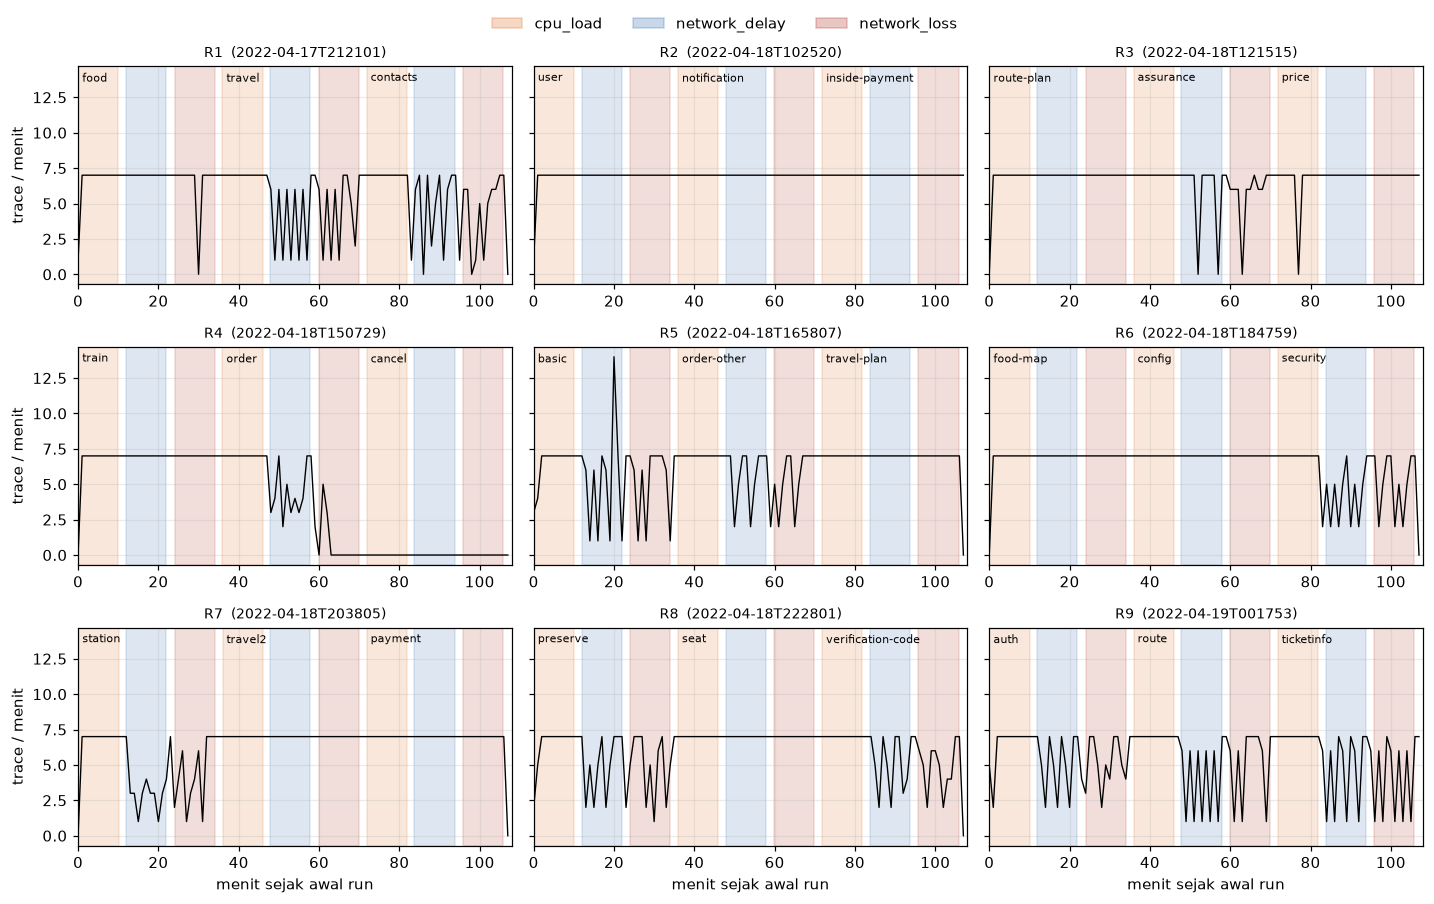

In [23]:
fig, axes = plt.subplots(3, 3, figsize=(13, 8), sharey=True)
for ax, run in zip(axes.ravel(), RUNS):
    fj, ft = load_fault(run), fault_table(run)
    s = TRAFFIC[run]
    ax.plot(s.index, s.values, lw=0.9, c="k")
    for r in ft.itertuples():
        ax.axvspan((r.t_start - fj["start"]) / 60, (r.t_end - fj["start"]) / 60, color=COLORS[r.fault], alpha=0.18)
    for svc, g in ft.groupby("service", sort=False):
        x = (g["t_start"].min() - fj["start"]) / 60 + 1
        ax.text(x, 0.97, re.sub(r"^ts-|-service$", "", svc), transform=ax.get_xaxis_transform(),
                va="top", fontsize=7)
    ax.set_title(f"{RID[run]}  ({run.split('D')[0]})", fontsize=9)
    ax.set_xlim(0, 108)
for ax in axes[-1]:
    ax.set_xlabel("menit sejak awal run")
for ax in axes[:, 0]:
    ax.set_ylabel("trace / menit")
handles = [plt.Rectangle((0, 0), 1, 1, color=c, alpha=0.3) for c in COLORS.values()]
fig.legend(handles, COLORS.keys(), loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.03))
plt.show()

> **Temuan 7**
> - Beban kerja **konstan: 7 trace per menit** di hampir semua run (median 7). Itu tanda skrip beban kerja deterministik.
> - **Lalu lintas turun tepat ketika fault jaringan mengenai service yang aktif**: R1 saat `travel` (menit ±48–70) dan `contacts` (menit ±83 ke atas), R3 saat `assurance`, R5 saat `basic`, R9 saat `auth/route/ticketinfo`, dan seterusnya. Pada **R2** (semua yang di-fault adalah `user`, `notification`, `inside-payment`, yaitu service tanpa span) garisnya **datar sempurna**: faultnya tidak mengganggu apa pun yang teramati.
> - **Catatan:** pada run lain ada penurunan singkat (±1 menit) ketika yang di-fault adalah service tanpa span, misalnya R1 menit ±30 (`food`, `network_loss`) dan R3 menit ±77 (`price`). Dugaan saya: sesekali ada permintaan yang memanggil service itu, macet, dan tidak sempat menghasilkan span. Ini belum saya telusuri.
> - **R4 bermasalah**: lalu lintas runtuh saat fault jaringan di `ts-order-service` (menit ±48–70) lalu **berhenti total sejak menit ±62**. Trace terakhir ada di menit 62,1 dari 107,7, dan ada **47 menit tanpa satu pun trace**. Metrics tetap berjalan sampai akhir. Artinya skrip beban kerja kemungkinan macet atau mati; jendela fault `cancel-service` di R4 praktis **tidak punya data trace/log sama sekali** (hanya metrics).
> - Jadi **jumlah trace per menit sendiri adalah sinyal fault** (dan juga perancu): model yang memakai volume trafik akan "mendeteksi" fault hanya dari turunnya beban.

## 8. Pemeriksaan D: cakupan service

**Mengapa penting.** Fault disuntikkan ke 27 service, tetapi hanya service yang benar-benar menerima trafik yang meninggalkan jejak di trace dan log.

**Cara memeriksa.** Hitung per service dan per run jumlah span unik (di dalam run) dan baris log, lalu tandai service yang di-fault tetapi tidak punya span.

In [24]:
ALL_SERVICES = sorted(p.stem for p in (DATA / f"TT.{RUNS[0]}" / "metrics").glob("*.csv"))
print("jumlah service (dari nama file metrics):", len(ALL_SERVICES))

cov_span = pd.DataFrame({RID[r]: CLEAN[r].groupby("service").size() for r in RUNS}).reindex(ALL_SERVICES).fillna(0).astype(int)
cov_log  = pd.DataFrame({RID[r]: LOGS[r].groupby("service").size() for r in RUNS}).reindex(ALL_SERVICES).fillna(0).astype(int)
ACTIVE = sorted(cov_span.index[(cov_span > 0).any(axis=1)])

print("== jumlah span unik (di dalam jendela run) per service per run ==")
display(cov_span)
print("== jumlah baris log per service per run ==")
display(cov_log)
print(f"Service yang pernah muncul di trace saat run berlangsung ('aktif'): {len(ACTIVE)} dari {len(ALL_SERVICES)}")
print("Service tanpa span sama sekali:", sorted(set(ALL_SERVICES) - set(ACTIVE)))

jumlah service (dari nama file metrics): 27
== jumlah span unik (di dalam jendela run) per service per run ==


,R1,R2,R3,R4,R5,R6,R7,R8,R9
service,,,,,,,,,
ts-assurance-service,89,108,97,56,98,99,97,94,84
ts-auth-service,178,216,208,112,196,198,194,189,163
ts-basic-service,356,432,416,224,368,396,388,376,334
ts-cancel-service,0,0,0,0,0,0,0,0,0
ts-config-service,0,0,0,0,0,0,0,0,0
ts-contacts-service,165,214,206,112,186,196,192,185,166
ts-food-map-service,0,0,0,0,0,0,0,0,0
ts-food-service,0,0,0,0,0,0,0,0,0
ts-inside-payment-service,0,0,0,0,0,0,0,0,0


== jumlah baris log per service per run ==


,R1,R2,R3,R4,R5,R6,R7,R8,R9
service,,,,,,,,,
ts-assurance-service,176,214,207,110,192,196,192,186,166
ts-auth-service,528,642,618,330,576,588,576,564,515
ts-basic-service,528,642,618,330,576,588,580,558,495
ts-cancel-service,0,0,0,0,0,0,0,0,0
ts-config-service,0,0,0,0,0,2,0,0,0
ts-contacts-service,710,856,824,448,744,784,768,740,664
ts-food-map-service,0,0,0,0,0,1,0,0,0
ts-food-service,3,0,0,0,0,0,0,0,0
ts-inside-payment-service,0,1,0,0,0,0,0,0,0


Service yang pernah muncul di trace saat run berlangsung ('aktif'): 13 dari 27
Service tanpa span sama sekali: ['ts-cancel-service', 'ts-config-service', 'ts-food-map-service', 'ts-food-service', 'ts-inside-payment-service', 'ts-notification-service', 'ts-payment-service', 'ts-price-service', 'ts-route-plan-service', 'ts-seat-service', 'ts-train-service', 'ts-travel-plan-service', 'ts-travel2-service', 'ts-user-service']


> **Temuan 8a.**
> - Hanya **13 dari 27 service** yang pernah muncul di trace saat run berlangsung, dan **himpunannya identik di semua run**. Sisanya, **14 service tanpa satu span pun**: `cancel, config, food-map, food, inside-payment, notification, payment, price, route-plan, seat, train, travel-plan, travel2, user`.
> - **Koreksi.** Di analisis awal saya sempat menyebut R7–R9 hanya punya 15 service di spans (vs 19 di run lain). Itu **artefak dari trace usang** di luar jendela run; setelah difilter, semua run punya 13 service yang sama.
> - Tabel log mengonfirmasi hal yang sama: service-service tadi hampir tidak punya baris log (0–4 baris per run; pada contoh yang saya periksa, `ts-food-service`, isinya error koneksi MongoDB).

In [25]:
# Untuk setiap fault: apakah service-nya punya span / log di run tempat ia di-fault?
rows = []
for r in RUNS:
    for svc in fault_table(r)["service"].unique():
        s = CLEAN[r][CLEAN[r]["service"] == svc]
        rows.append({"run": RID[r], "service": svc,
                     "span_total": len(s), "span_server": int((s["kind"] == "server").sum()),
                     "span_client": int((s["kind"] == "client").sum()),
                     "baris_log": int((LOGS[r]["service"] == svc).sum())})
fc = pd.DataFrame(rows)
fc["terobservasi_di_trace"] = fc["span_total"] > 0
display(fc)
print("Service yang di-fault tetapi TIDAK punya span sama sekali:", int((~fc["terobservasi_di_trace"]).sum()), "dari", len(fc))

,run,service,span_total,span_server,span_client,baris_log,terobservasi_di_trace
0,R1,ts-food-service,0,0,0,3,False
1,R1,ts-travel-service,680,85,595,2301,True
2,R1,ts-contacts-service,165,165,0,710,True
3,R2,ts-user-service,0,0,0,1,False
4,R2,ts-notification-service,0,0,0,0,False
5,R2,ts-inside-payment-service,0,0,0,1,False
6,R3,ts-route-plan-service,0,0,0,0,False
7,R3,ts-assurance-service,97,97,0,207,True
8,R3,ts-price-service,0,0,0,2,False
9,R4,ts-train-service,0,0,0,2,False


Service yang di-fault tetapi TIDAK punya span sama sekali: 14 dari 27


> **Temuan 8b.** **14 dari 27** fault (≈ 52%) disuntikkan ke service yang **tidak punya span sama sekali** pada run itu. Untuk fault-fault ini, `network_delay` dan `network_loss` **tidak meninggalkan span** dan di log hanya segelintir baris; dampak tak langsungnya paling banyak terlihat sebagai penurunan sesaat jumlah trace (lihat Temuan 7). Satu-satunya modalitas yang masih bisa melihatnya adalah **metrics** (dan itu pun hanya `cpu_load`, lihat bagian 9).
> Perhatikan juga: pada `ts-travel-service` di R1 ada 680 span tetapi hanya 85 yang `server` (595 `client`); jumlah dan makna span berbeda menurut jenisnya, jadi pilih jenis span dengan sadar saat menghitung latensi.

## 9. Pemeriksaan E: desain label dan seberapa terlihat tiap fault

### 9.1 Desain eksperimen

Sel berikut menghitung berapa kali tiap pasangan (service, jenis fault) muncul, dan di run mana.

In [26]:
design = pd.concat([fault_table(r).assign(run=RID[r]) for r in RUNS], ignore_index=True)
print("jumlah kejadian fault:", len(design))
print("service unik yang di-fault:", design["service"].nunique())
print("durasi fault (detik):", design["duration"].unique())
cnt = design.groupby(["service", "fault"]).size().unstack(fill_value=0)
print("(service, jenis fault) yang punya TEPAT 1 contoh:", int((cnt == 1).sum().sum()), "dari", cnt.size)
display(design.pivot_table(index="service", columns="fault", values="run", aggfunc="first"))

jumlah kejadian fault: 81
service unik yang di-fault: 27
durasi fault (detik): [600]
(service, jenis fault) yang punya TEPAT 1 contoh: 81 dari 81


fault,cpu_load,network_delay,network_loss
service,,,
ts-assurance-service,R3,R3,R3
ts-auth-service,R9,R9,R9
ts-basic-service,R5,R5,R5
ts-cancel-service,R4,R4,R4
ts-config-service,R6,R6,R6
ts-contacts-service,R1,R1,R1
ts-food-map-service,R6,R6,R6
ts-food-service,R1,R1,R1
ts-inside-payment-service,R2,R2,R2


> **Temuan 9.1**
> - Total **81 kejadian fault** (9 run × 9), semuanya **600 detik**, mengenai **27 service**, tiap service **hanya di satu run**.
> - Setiap pasangan (service, jenis fault) punya **tepat 1 contoh** (81 dari 81). Tidak ada pengulangan.
> - **Konsekuensi untuk pemodelan:** tidak ada replikasi, jadi tidak mungkin membedakan "efek fault" dari "kebetulan satu run". Pembagian latih/uji yang acak per baris akan bocor (jendela fault yang sama muncul di kedua sisi); bagi **per kejadian fault** atau per run. Karena semua service hanya di-fault di satu run, pembagian per run berarti fault pada service uji **tidak pernah dilihat** saat latih.

### 9.2 Fault apa yang terlihat di modalitas apa?

**Latensi (trace).** Untuk tiap jendela fault, kita bandingkan median durasi span milik service yang di-fault **di dalam jendela** dengan **di luar jendela** (baseline run yang sama). Rasio 1 = tidak berubah. Dipakai span `server` dan `client` karena sebagian service hanya punya salah satunya.

In [27]:
eff = eff8.copy()
eff["rasio_median"] = eff["median_di_jendela_ms"] / eff["median_baseline_ms"]
agg = eff.groupby("fault").agg(
    jendela=("fault", "size"),
    ada_span=("n_di_jendela", lambda s: int((s > 0).sum())),
    median_rasio=("rasio_median", "median"),
    rasio_maks=("rasio_median", "max"),
    jendela_rasio_gt_2=("rasio_median", lambda s: int((s > 2).sum())),
)
display(agg.round(2))
print("Jendela dengan lonjakan latensi (rasio > 5) — baris-baris pertama:")
display(eff[eff["rasio_median"] > 5].sort_values("rasio_median", ascending=False).round(1).head(15))

,jendela,ada_span,median_rasio,rasio_maks,jendela_rasio_gt_2
fault,,,,,
cpu_load,27,13,0.85,1.23,0
network_delay,27,13,1396.81,3008.62,11
network_loss,27,13,296.59,3974.56,10


Jendela dengan lonjakan latensi (rasio > 5) — baris-baris pertama:


,run,service,fault,n_di_jendela,median_di_jendela_ms,n_baseline,median_baseline_ms,rasio_median
56,R7,ts-station-service,network_loss,3,9636.3,216,2.4,3974.6
38,R5,ts-basic-service,network_loss,8,12172.1,268,3.8,3241.6
55,R7,ts-station-service,network_delay,11,7294.4,216,2.4,3008.6
7,R1,ts-contacts-service,network_delay,13,7290.6,120,2.5,2943.9
4,R1,ts-travel-service,network_delay,40,7293.2,496,3.2,2265.3
52,R6,ts-security-service,network_delay,16,10302.1,213,4.8,2132.5
53,R6,ts-security-service,network_loss,7,10201.0,213,4.8,2111.6
37,R5,ts-basic-service,network_delay,32,7296.7,268,3.8,1943.2
40,R5,ts-order-other-service,network_delay,8,5149.1,63,3.5,1475.4
76,R9,ts-route-service,network_delay,25,3011.5,279,2.2,1396.8


> **Temuan 9.2a (latensi).**
> - `network_delay`: median rasio **±1.400×**; `network_loss`: **±300×**; `cpu_load`: **0,85×** (tidak ada efek).
> - Dari 13 jendela yang punya span, **11** (delay) dan **10** (loss) naik lebih dari 2×. Contoh: `ts-station-service` normal 2,4 ms, saat `network_delay` median 7.294 ms; `ts-travel-service` di R1 dari 3,2 ms menjadi 7.293 ms (×2.265).
> - Pola 3.000–10.000 ms yang berulang kemungkinan akibat *timeout* dan percobaan ulang (*retry*), bukan penundaan jaringan murni.
> - `cpu_load` **tidak terlihat di latensi** sama sekali pada beban rendah ini (7 trace per menit).

**Metrics.** Untuk tiap jendela, rasio rata-rata metrik **di dalam jendela / di luar jendela** pada service yang di-fault (jam metrics sama dengan `fault.json`, tanpa geseran). Tabel A: semua 27 service. Tabel B: hanya 13 service aktif. Tabel C: nilai absolut CPU.

In [28]:
# Efek fault pada METRICS service yang di-fault: rata-rata di dalam jendela vs di luar jendela
# (jam fault.json = jam metrics, jadi TIDAK perlu digeser).
METRIC_COLS = ["cpu_usage_total", "memory_usage", "rx_bytes", "tx_bytes"]
rows = []
for run in RUNS:
    ft = fault_table(run)
    for svc, g in ft.groupby("service", sort=False):
        m = load_metrics(run, svc)
        near = np.zeros(len(m), bool)
        for r in g.itertuples():
            near |= ((m["timestamp"] >= r.t_start - 30) & (m["timestamp"] < r.t_end + 30)).to_numpy()
        base = m[~near]
        for r in g.itertuples():
            w = m[(m["timestamp"] >= r.t_start) & (m["timestamp"] < r.t_end)]
            row = {"run": RID[run], "service": svc, "fault": r.fault, "aktif": svc in ACTIVE,
                   "cpu_di_jendela": w["cpu_usage_total"].mean(), "cpu_baseline": base["cpu_usage_total"].mean()}
            for c in METRIC_COLS:
                row[c + "_ratio"] = (w[c].mean() + 1e-9) / (base[c].mean() + 1e-9)
            rows.append(row)
em = pd.DataFrame(rows)
rcols = [c + "_ratio" for c in METRIC_COLS]

print("Rasio = rata-rata di jendela fault / rata-rata di luar jendela (median lintas jendela). 1.0 = tidak berubah.\n")
print("A. Semua 27 service yang di-fault:")
display(em.groupby("fault")[rcols].median().round(2))
print("B. Hanya service AKTIF (yang punya trafik):")
display(em[em["aktif"]].groupby("fault")[rcols].median().round(2))
print("C. Nilai absolut CPU (cpu_usage_total, rata-rata) di dalam vs di luar jendela, median lintas jendela:")
display(em.groupby("fault")[["cpu_di_jendela", "cpu_baseline"]].median().round(4))

Rasio = rata-rata di jendela fault / rata-rata di luar jendela (median lintas jendela). 1.0 = tidak berubah.

A. Semua 27 service yang di-fault:


,cpu_usage_total_ratio,memory_usage_ratio,rx_bytes_ratio,tx_bytes_ratio
fault,,,,
cpu_load,47634.78,1.03,0.94,1.00
network_delay,1.07,1.00,0.89,0.92
network_loss,1.10,1.00,1.48,0.82


B. Hanya service AKTIF (yang punya trafik):


,cpu_usage_total_ratio,memory_usage_ratio,rx_bytes_ratio,tx_bytes_ratio
fault,,,,
cpu_load,42918.85,1.03,0.95,1.03
network_delay,1.00,1.00,1.04,0.82
network_loss,1.05,1.00,1.34,0.63


C. Nilai absolut CPU (cpu_usage_total, rata-rata) di dalam vs di luar jendela, median lintas jendela:


,cpu_di_jendela,cpu_baseline
fault,,
cpu_load,46.7705,0.001
network_delay,0.0010,0.001
network_loss,0.0011,0.001


> **Temuan 9.2b (metrics).**
> - `cpu_load`: CPU naik dari **0,001 menjadi ±47** (±47.000×) dan itu **satu-satunya** sinyal yang jelas. Memori, rx, dan tx tidak berubah (rasio ≈ 1).
> - `network_delay` dan `network_loss`: **CPU dan memori tidak berubah** (rasio 1,0–1,1). `rx/tx` bergeser sedikit dan tidak konsisten (pada service aktif `network_loss`: rx ×1,34, tx ×0,63), jadi sinyalnya lemah dan bercampur dengan variasi normal.
> - **Ringkasan silang modalitas:** `cpu_load` hanya terlihat di **metrics**; `network_delay` dan `network_loss` hanya terlihat di **trace (latensi)**, dan itu pun hanya untuk service yang punya trafik. Tidak ada satu modalitas pun yang cukup untuk ketiga jenis fault.

**Visual.** Tiga panel berikut memperlihatkan ketiga modalitas pada satu service yang aktif, `ts-travel-service` di R1: latensi span (skala log), CPU, dan lalu lintas jaringan. Warna latar = jenis fault. Jam spans dikoreksi −8 jam agar sejajar dengan label.

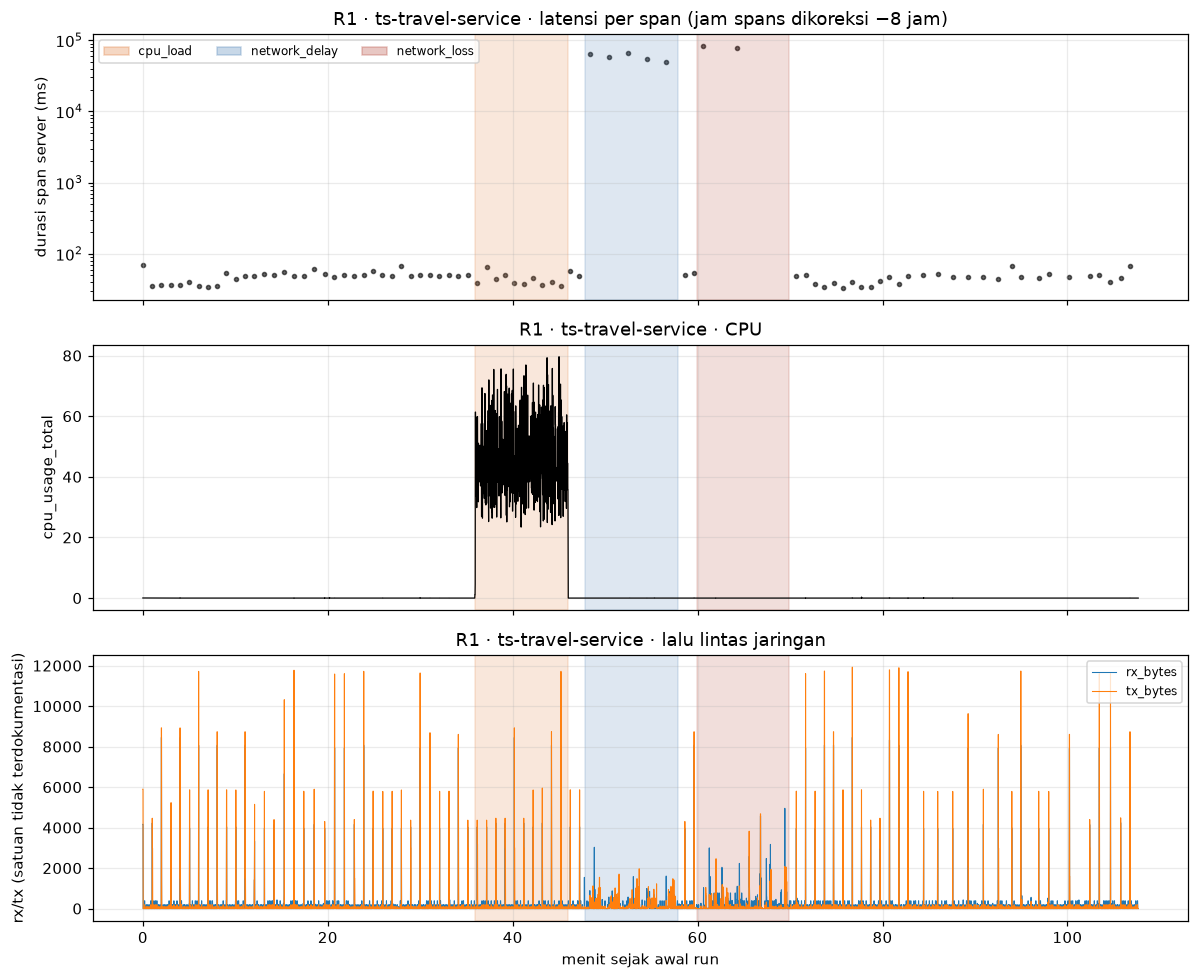

In [29]:
run = RUNS[0]
fj, ft = load_fault(run), fault_table(run)
sp = CLEAN[run]
svc = "ts-travel-service"

def shade(ax):
    for r in ft[ft["service"] == svc].itertuples():
        ax.axvspan((r.t_start - fj["start"]) / 60, (r.t_end - fj["start"]) / 60, color=COLORS[r.fault], alpha=0.18)

fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)

# (a) latensi span server ts-travel-service (skala log). Jam spans dikurangi OFFSET agar sejajar dengan jam fault.json.
s = sp[(sp["service"] == svc) & (sp["kind"] == "server")]
axes[0].scatter((s["start"] - OFFSET_S - fj["start"]) / 60, s["dur"] / 1000, s=7, c="k", alpha=0.6)
axes[0].set_yscale("log"); axes[0].set_ylabel("durasi span server (ms)")
axes[0].set_title(f"R1 · {svc} · latensi per span (jam spans dikoreksi −{OFFSET_S // 3600} jam)"); shade(axes[0])
handles = [plt.Rectangle((0, 0), 1, 1, color=c, alpha=0.3) for c in COLORS.values()]
axes[0].legend(handles, COLORS.keys(), loc="upper left", ncol=3, fontsize=8, frameon=True)

# (b) CPU
m = load_metrics(run, svc)
axes[1].plot((m["timestamp"] - fj["start"]) / 60, m["cpu_usage_total"], lw=0.8, c="k")
axes[1].set_ylabel("cpu_usage_total"); axes[1].set_title(f"R1 · {svc} · CPU"); shade(axes[1])

# (c) rx / tx
axes[2].plot((m["timestamp"] - fj["start"]) / 60, m["rx_bytes"], lw=0.7, label="rx_bytes")
axes[2].plot((m["timestamp"] - fj["start"]) / 60, m["tx_bytes"], lw=0.7, label="tx_bytes")
axes[2].set_ylabel("rx/tx (satuan tidak terdokumentasi)"); axes[2].set_xlabel("menit sejak awal run")
axes[2].legend(loc="upper right", fontsize=8); axes[2].set_title(f"R1 · {svc} · lalu lintas jaringan"); shade(axes[2])
plt.show()

**Cara membaca.**

- *Panel atas* (latensi): span normal ±50 ms. Di jendela `cpu_load` (oranye) **tidak ada perubahan**. Di jendela `network_delay` dan `network_loss` (biru dan merah) hanya ada **segelintir span** dengan durasi **50–80 detik** (naik ±1.000×) karena hampir semua permintaan macet (lihat bagian 7).
- *Panel tengah* (CPU): lompatan CPU **persis** di jendela oranye dan hanya di sana.
- *Panel bawah* (jaringan): lonjakan tx yang teratur (mengikuti pola beban kerja) **menghilang** di jendela `network_delay` dan digantikan aktivitas rx/tx yang kecil dan acak. Terlihat jelas pada satu service aktif, tetapi seperti tabel di atas, tidak konsisten antar service.
- Bahwa ketiga panel sejajar rapi adalah **validasi visual** dari koreksi offset 8 jam di bagian 5.

### 9.3 Status HTTP dan tag error

Pemeriksaan terakhir: apakah kegagalan terlihat sebagai kode status? (Pada data yang sudah bersih, dedup, di dalam run.)

In [30]:
allsp = pd.concat([CLEAN[r].assign(run=RID[r]) for r in RUNS], ignore_index=True)
print("status HTTP (span unik, di dalam jendela run):")
print(allsp["status"].value_counts(dropna=False).to_string())
print("\nspan dengan tag 'error' :", int(allsp["error"].notna().sum()), "dari", len(allsp))

bad = allsp[(allsp["status"].fillna(0).astype(float) >= 400) | allsp["error"].notna()]
display(bad.groupby(["run", "service", "op", "kind", "status"], dropna=False).size().rename("n").reset_index())

status HTTP (span unik, di dalam jendela run):
status
200.0    33627
500.0        8
NaN          7

span dengan tag 'error' : 7 dari 33642


,run,service,op,kind,status,n
0,R5,ts-preserve-service,GET,client,500.0,1
1,R5,ts-preserve-service,preserve,server,500.0,1
2,R5,ts-security-service,GET,client,500.0,1
3,R5,ts-security-service,check,server,500.0,1
4,R7,ts-order-service,POST,client,NaN,2
5,R7,ts-order-service,queryOrdersForRefresh,server,500.0,2
6,R9,ts-travel-service,GET,client,500.0,1
7,R9,ts-travel-service,queryInfo,server,500.0,1


> **Temuan 9.3.** Dari **33.642** span unik, **33.627 berstatus 200**; hanya **8 berstatus 500** (R5: 4, R7: 2, R9: 2) dan 7 tanpa status; hanya 7 yang bertag `error`. Itu ≈ **0,04%**. **Sinyal kegagalan di trace hampir seluruhnya ada di latensi, bukan di kode status.** Label berbasis error akan sangat tidak seimbang (puluhan ribu span normal vs belasan error).
> (Run no-fault tidak punya satu pun status non-200, jadi 500 itu memang terkait fault.)
> **Koreksi.** Di analisis awal saya menyebut 12/2/8 span HTTP 500 pada tiga run; angka itu dihitung **sebelum dedup**. Yang benar: 4/2/2.

## 10. Pemeriksaan F: baseline tanpa fault (`no fault/`)

**Mengapa penting.** Untuk mendeteksi anomali perlu tahu seperti apa "normal". Run no-fault adalah acuan itu.

**Catatan penting dari bagian 3.1:** di run berfault nyaris tidak ada waktu normal (fault berurutan dengan jeda ±2 menit). Kita ukur seberapa banyak data "normal" yang tersisa di sana, dan bandingkan dengan run no-fault.

**Cara membaca arsip.** Tiga run dibaca langsung dari `.tar.xz` (sekitar 90 MB terdekompresi per run) **tanpa diekstrak ke disk**. Hanya dua dari tiga yang punya `fault.json` (isinya `faults: []`).

In [31]:
def read_run_from_archive(path):
    """Baca satu run LANGSUNG dari arsip tar.xz (tanpa ekstrak ke disk)."""
    out = {"name": None, "metrics": {}, "spans": None, "logs": None}
    with tarfile.open(path, "r:xz") as tf:
        for m in tf:
            if not m.isfile():
                continue
            parts = Path(m.name).parts
            out["name"] = out["name"] or parts[0]
            fobj = tf.extractfile(m)
            if parts[-1] == "spans.json":
                out["spans"] = json.load(fobj)
            elif parts[-1] == "logs.json":
                out["logs"] = json.load(fobj)
            elif len(parts) >= 3 and parts[-2] == "metrics":
                out["metrics"][Path(parts[-1]).stem] = pd.read_csv(fobj)
    return out

NF_FILES = [NOFAULT / "TT-no-fault.txz",
            NOFAULT / "TT.2022-04-21T105158D2022-04-21T130705.tar.xz",
            NOFAULT / "TT.2022-04-21T153246D2022-04-21T174753.tar.xz"]
NF = {}
for p in NF_FILES:
    r = read_run_from_archive(p)
    NF[r["name"][3:]] = r
    print("dibaca:", p.name, "->", r["name"], "| metrics:", len(r["metrics"]), "service")

fault_json_files = sorted(p.name for p in NOFAULT.glob("TT.fault-*.json"))
print("\nfile label (fault.json) yang tersedia di folder 'no fault':", fault_json_files)

dibaca: TT-no-fault.txz -> TT.2022-04-20T134450D2022-04-20T155957 | metrics: 27 service
dibaca: TT.2022-04-21T105158D2022-04-21T130705.tar.xz -> TT.2022-04-21T105158D2022-04-21T130705 | metrics: 27 service
dibaca: TT.2022-04-21T153246D2022-04-21T174753.tar.xz -> TT.2022-04-21T153246D2022-04-21T174753 | metrics: 27 service

file label (fault.json) yang tersedia di folder 'no fault': ['TT.fault-2022-04-21T105158D2022-04-21T130705.json', 'TT.fault-2022-04-21T153246D2022-04-21T174753.json']


In [32]:
NF_IDS = {run: f"N{i}" for i, run in enumerate(NF, 1)}
rows = []
for run, r in NF.items():
    mt = r["metrics"]["ts-order-service"]["timestamp"]
    lo, hi = mt.min() + OFFSET_S, mt.max() + OFFSET_S                 # jendela run pada jam spans/logs
    lg = parse_logs(r["logs"])
    raw_df = flatten_spans(r["spans"])
    uniq = raw_df.drop_duplicates(["traceID", "spanID"]).reset_index(drop=True)
    inrun = uniq[trace_in_window(uniq, lo, hi)].reset_index(drop=True)
    NF[run]["spans_df"], NF[run]["logs_df"], NF[run]["window"] = inrun, lg, (lo, hi)
    rows.append({"run": NF_IDS[run], "folder": run, "ada_fault.json": (NOFAULT / f"TT.fault-{run}.json").exists(),
                 "metrics_awal (UTC, jam metrics)": utc_str(mt.min()), "durasi_menit": (mt.max() - mt.min()) / 60,
                 "log_pertama - metrics_pertama (jam)": (lg["t"].min() - mt.min()) / 3600,
                 "baris_span": len(raw_df), "span_unik": len(uniq), "span_di_run": len(inrun),
                 "n_service_di_run": inrun["service"].nunique(),
                 "span_status_non200": int((inrun["status"].fillna(200) != 200).sum())})
nfp = pd.DataFrame(rows).set_index("run")
display(nfp.round(2))

,folder,ada_fault.json,"metrics_awal (UTC, jam metrics)",durasi_menit,log_pertama - metrics_pertama (jam),baris_span,span_unik,span_di_run,n_service_di_run,span_status_non200
run,,,,,,,,,,
N1,2022-04-20T134450D2022-04-20T155957,False,04-19 21:44:50,135.1,8.02,32340,7978,5522,13,0
N2,2022-04-21T105158D2022-04-21T130705,True,04-20 18:51:58,135.1,8.02,32420,7941,5522,13,0
N3,2022-04-21T153246D2022-04-21T174753,True,04-20 23:32:46,135.1,8.02,32420,7912,5522,13,0


> **Temuan 10a.**
> - 3 run no-fault, masing-masing **135,1 menit** (lebih panjang dari run berfault, 107,7 menit), 27 service metrics, 13 service di trace (sama dengan run berfault).
> - **N1 (2022-04-20) tidak punya `fault.json`.** Jendela waktunya harus diambil dari metrics, seperti yang dilakukan sel di atas.
> - **Offset 8 jam yang sama ada di run no-fault** (`log_pertama − metrics_pertama` = 8,02 jam), jadi koreksinya berlaku untuk seluruh dataset.
> - Spans no-fault juga **terduplikasi** (±32.000 baris → ±7.900 unik → 5.522 di dalam run).
> - Jumlah span di dalam run **identik (5.522) di ketiga run**, dan tidak ada satu pun status non-200. Itu menguatkan dugaan beban kerja yang deterministik dan stabil.

In [33]:
# Latensi 'normal': run no-fault (N1-N3) vs bagian run berfault yang berada di LUAR jendela fault (R1-R9).
def per_service_median(df, kinds=("server",)):
    d = df[df["kind"].isin(kinds)]
    return d.groupby("service")["dur"].median() / 1000

def outside_fault_windows(run):
    """Span di dalam run, di luar jendela fault MANAPUN (+- 60 s) pada semua service."""
    ft = fault_table(run)
    sp = CLEAN[run]
    near = np.zeros(len(sp), bool)
    for r in ft.itertuples():
        near |= ((sp["start"] >= r.t_start + OFFSET_S - 60) & (sp["start"] < r.t_end + OFFSET_S + 60)).to_numpy()
    return sp[~near]

normal_in_fault_runs = pd.concat([outside_fault_windows(r) for r in RUNS], ignore_index=True)
print("span 'normal' yang tersisa di luar jendela fault (R1-R9):", len(normal_in_fault_runs),
      "dari", sum(len(CLEAN[r]) for r in RUNS), "span di dalam run")

med_fault_runs = per_service_median(normal_in_fault_runs).rename("R1-R9 di luar fault")
med_nf = pd.concat([per_service_median(NF[r]["spans_df"]).rename(NF_IDS[r]) for r in NF], axis=1)
display(pd.concat([med_nf, med_fault_runs], axis=1).round(2))
print("Median durasi span SERVER per service (ms).")

span 'normal' yang tersisa di luar jendela fault (R1-R9): 328 dari 33642 span di dalam run


,N1,N2,N3,R1-R9 di luar fault
service,,,,
ts-assurance-service,1.72,1.62,1.60,1.65
ts-auth-service,111.92,113.58,113.96,113.34
ts-basic-service,5.46,5.53,5.51,5.52
ts-contacts-service,2.71,2.91,2.82,2.65
ts-order-other-service,3.28,3.29,3.21,3.26
ts-order-service,10.53,9.96,10.17,8.79
ts-preserve-service,22.36,22.81,22.73,22.17
ts-route-service,2.21,2.21,2.17,2.17
ts-security-service,14.15,14.18,14.26,14.29


Median durasi span SERVER per service (ms).


> **Temuan 10b.**
> - Median latensi per service **stabil antar ketiga run no-fault** (mis. `ts-travel-service` 43,95 / 44,06 / 44,03 ms; `ts-auth-service` 112–114 ms): baseline-nya konsisten.
> - Di run berfault **hanya 328 dari 33.642 span (≈ 1%)** yang berada di luar semua jendela fault (±60 detik). Medianya pun mirip no-fault, dengan satu perbedaan kecil di `ts-order-service` (8,8 vs ±10 ms) yang saya tidak telusuri lebih jauh.
> - **Kesimpulan:** "waktu normal" di dalam run berfault nyaris tidak ada. **Gunakan run no-fault (N1–N3) sebagai baseline normal**, dan jangan mencoba mengambil baseline dari sela-sela fault.

In [34]:
# Distribusi CPU service pada run no-fault vs pada run berfault (di luar jendela fault service itu sendiri)
rows = []
for run, r in NF.items():
    for svc, m in r["metrics"].items():
        rows.append({"sumber": NF_IDS[run], "service": svc, "cpu_median": m["cpu_usage_total"].median(),
                     "cpu_p99": m["cpu_usage_total"].quantile(.99), "cpu_max": m["cpu_usage_total"].max()})
for run in RUNS:
    ft = fault_table(run)
    for svc in [p.stem for p in (DATA / f"TT.{run}" / "metrics").glob("*.csv")]:
        m = load_metrics(run, svc)
        near = np.zeros(len(m), bool)
        for r in ft[ft["service"] == svc].itertuples():
            near |= ((m["timestamp"] >= r.t_start - 30) & (m["timestamp"] < r.t_end + 30)).to_numpy()
        mb = m[~near]
        rows.append({"sumber": RID[run], "service": svc, "cpu_median": mb["cpu_usage_total"].median(),
                     "cpu_p99": mb["cpu_usage_total"].quantile(.99), "cpu_max": mb["cpu_usage_total"].max()})
cpu = pd.DataFrame(rows)
piv = cpu.pivot_table(index="service", columns="sumber", values="cpu_p99")
display(piv.round(2))
print("cpu_usage_total persentil-99 per service. Kolom N* = tanpa fault; R* = berfault (di luar jendela fault service itu).")

sumber,N1,N2,N3,R1,R2,R3,R4,R5,R6,R7,R8,R9
service,,,,,,,,,,,,
ts-assurance-service,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
ts-auth-service,0.11,0.11,0.11,0.11,0.11,0.11,0.06,0.11,0.11,0.11,0.07,0.07
ts-basic-service,0.01,0.01,0.01,0.01,0.01,0.01,0.00,0.01,0.01,0.01,0.01,0.01
ts-cancel-service,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
ts-config-service,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
ts-contacts-service,0.01,0.01,0.01,0.00,0.01,0.01,0.00,0.01,0.01,0.01,0.01,0.01
ts-food-map-service,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
ts-food-service,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
ts-inside-payment-service,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


cpu_usage_total persentil-99 per service. Kolom N* = tanpa fault; R* = berfault (di luar jendela fault service itu).


> **Temuan 10c.** Persentil-99 CPU per service di run no-fault dan di bagian normal run berfault **hampir sama**, kecuali di R4, R8, dan R9 untuk `ts-auth-service` (±0,06–0,07 vs 0,11). Itu bukan fault: CPU service mengikuti beban, dan di run-run tersebut trafik sempat turun (lihat bagian 7), meski saya tidak menguji hubungan sebab-akibatnya. CPU di service aktif kecil (0,00–0,11) dan sangat stabil; pada service tak aktif ≈ 0.

## 11. Ringkasan temuan dan resep pembersihan

| # | Pemeriksaan | Hasil | Tindakan sebelum modelling |
|---|---|---|---|
| 1 | Sinkronisasi waktu | `fault.json` dan metrics **8 jam di belakang** spans/logs (3 bukti independen di run berfault; konsisten di run no-fault) | geser spans/logs `−28.800 s` (atau label/metrics `+28.800 s`) |
| 2 | Duplikasi spans | **75% baris duplikat**, salinan identik | dedup `(traceID, spanID)` |
| 3 | Trace di luar jendela | 10–49% span di luar waktu run; ±100 trace usang di setiap file; run bersebelahan saling tumpang tindih | filter per-trace ke jendela run |
| 4 | Kontinuitas trafik | 7 trace/menit konstan; **R4 mati sejak menit ±62**; trafik turun saat fault di service aktif | buang/tandai segmen R4 tanpa data; waspadai volume trafik sebagai perancu |
| 5 | Cakupan service | hanya **13/27** service punya trafik; **14/27 fault** mengenai service tanpa trafik | untuk fault itu hanya metrics yang berguna (`cpu_load`) |
| 6 | Desain label | 81 fault, tiap (service, fault) **1 contoh**, tanpa replikasi | pisahkan latih/uji per kejadian fault atau per run, bukan per baris |
| 7 | Efek tiap modalitas | `cpu_load` → hanya metrics (CPU ×47.000); `network_*` → hanya latensi trace (×300–1.400); status HTTP hampir selalu 200 | gunakan fitur latensi, bukan status; gabungkan modalitas |
| 8 | Baseline | di run berfault ≈ 1% data normal | pakai N1–N3 sebagai baseline normal |
| 9 | Duplikasi arsip | `TT-all.txz` = salinan `data/` | muat satu saja |
| 10 | Logs | semua `INFO`; 40% baris adalah `Span reported`; banyak service kosong | parse isi pesan; gunakan `Span reported` untuk join ke trace |

**Hal yang belum diperiksa** (sengaja dibiarkan terbuka): satuan pasti kolom metrics (`cpu_usage_total`, `rx/tx`); penyebab duplikasi dan offset 8 jam (hanya diduga); kualitas isi `logs` per span di dalam trace; dan apakah efek fault merambat ke service tetangga (kolom *downstream/upstream*), karena analisis di sini hanya melihat service yang di-fault.

### Resep: satu fungsi untuk memuat satu run yang bersih dan sejajar

Fungsi di bawah merangkum koreksi 1–3: dedup (sudah di `SPANS`), filter ke jendela run, dan geser spans/logs ke **jam `fault.json`/metrics** (jam label). Hasilnya siap dipakai: `spans`, `logs`, `metrics` (per service), dan `windows` (label). Sel akhir adalah uji cepat: setelah dibersihkan, span `ts-travel-service` di jendela `network_delay` R1 harus lambat.

In [35]:
def load_clean_run(run):
    """Satu run berfault yang sudah dibersihkan dan SEJAJAR WAKTU.

    Semua waktu dinyatakan pada jam fault.json/metrics (epoch detik; = UTC sebenarnya - 8 jam):
      - spans: dedup (traceID, spanID); hanya trace yang mulai di dalam jendela run; start digeser -OFFSET_S
      - logs : hanya baris di dalam jendela run; t digeser -OFFSET_S
      - metrics: apa adanya
      - windows: label fault (service, fault, t_start, t_end)
    """
    fj = load_fault(run)
    lo, hi = fj["start"], fj["end"]
    sp = SPANS[run]
    sp = sp[trace_in_window(sp, lo + OFFSET_S, hi + OFFSET_S)].copy()
    sp["start"] -= OFFSET_S
    lg = LOGS[run]
    lg = lg[(lg["t"] - OFFSET_S >= lo - 60) & (lg["t"] - OFFSET_S <= hi + 60)].copy()
    lg["t"] -= OFFSET_S
    metrics = {p.stem: pd.read_csv(p) for p in sorted((DATA / f"TT.{run}" / "metrics").glob("*.csv"))}
    return {"run": run, "windows": fault_table(run), "spans": sp.reset_index(drop=True),
            "logs": lg.reset_index(drop=True), "metrics": metrics, "start": lo, "end": hi}

# Uji cepat: setelah dibersihkan, span ts-travel-service pada jendela network_delay R1 harus lambat.
d = load_clean_run(RUNS[0])
w = d["windows"].query("service == 'ts-travel-service' and fault == 'network_delay'").iloc[0]
s = d["spans"].query("service == 'ts-travel-service' and kind == 'server'")
inside = s[(s["start"] >= w.t_start) & (s["start"] < w.t_end)]
outside = s[(s["start"] < w.t_start - 60) | (s["start"] >= w.t_end + 60)]
print(f"{RID[RUNS[0]]}: span={len(d['spans'])}, log={len(d['logs'])}, service metrics={len(d['metrics'])}, jendela fault={len(d['windows'])}")
print(f"median durasi server ts-travel-service: di jendela network_delay = {inside['dur'].median()/1000:,.0f} ms, di luar = {outside['dur'].median()/1000:,.1f} ms")

R1: span=3591, log=8995, service metrics=27, jendela fault=9
median durasi server ts-travel-service: di jendela network_delay = 58,863 ms, di luar = 48.3 ms


**Langkah berikutnya** yang disarankan:

1. Bangun tabel fitur per (service, jendela waktu) dari `load_clean_run`: latensi (median/p95 `dur` per service, juga selisih client − server), CPU, jumlah trace per menit.
2. Beri label per jendela waktu dari `windows`; waspadai 14 service tanpa trafik dan segmen R4 setelah menit ±62.
3. Tentukan skema pembagian latih/uji **sebelum** membuat fitur (lihat Temuan 9.1).
4. Gunakan N1–N3 untuk menentukan ambang "normal".